In [24]:
import sys
import os
from typing import NamedTuple
import math
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import pickle

from sklearn.model_selection import TimeSeriesSplit, StratifiedKFold
import jax


sys.path.append(os.path.join(os.getcwd(), '../'))
from utils_worm import artificializer
from utils_worm import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils
from models import bom
from models import hgm


# jax.config.update("jax_enable_x64", True)

In [25]:
import importlib
importlib.reload(artificializer)
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(bom)
importlib.reload(hgm)

<module 'models.hgm' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/models/hgm.py'>

# Functions

In [26]:
def seperate_predictions(file_ids, columns, models_spn_man_rec_res_pres):
	models_spn = [
		[
			pd.DataFrame(data=np.array(split[0])[None], columns=columns[i]) for split in models_spn_man_rec_res_pres[i]
		] for i in range(len(file_ids))
	]
	models_man = [
		[
			pd.DataFrame(data=np.array(split[1]), columns=[f'M{i}' for i in range(np.array(split[1]).shape[1])]) for split in models_spn_man_rec_res_pres[i]
		] for i in range(len(file_ids))
	]
	(models_rec,
	 models_res,
	 models_pres) = tuple(
		[
			[
				pd.DataFrame(data=np.array(split[m]), columns=columns[i]) for split in models_spn_man_rec_res_pres[i]
			] for i in range(len(file_ids))
		] for m in [2, 3, 4]
	)
	return models_spn, models_man, models_rec, models_res, models_pres

In [27]:
def assemble(boms_scores_per_neuron, hgms_scores_per_neuron):
	neurons_labels = [scores_per_neuron[0].columns for scores_per_neuron in hgms_scores_per_neuron]

	boms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in hgms_scores_per_neuron]

	neuron_scores = dict()
	boms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in hgms_scores_per_neuron]
	for label_list, score_bom_list, score_hgm_list in zip(neurons_labels, boms_scores_per_neuron_avg, hgms_scores_per_neuron_avg):
		sort_indices = np.argsort(score_hgm_list)[::-1]
		label_list = label_list[sort_indices]
		score_bom_list = score_bom_list[sort_indices]
		score_hgm_list = score_hgm_list[sort_indices]

		for i in range(len(label_list)):
			label = label_list[i]
			if label != '' and label[-1] != '_':
				score_bom_new, score_hgm_new = np.array(score_bom_list[i]), np.array(score_hgm_list[i])
				if len(score_hgm_new.shape) == 0:
					score_bom_new = score_bom_new.reshape(1, 1)
					score_hgm_new = score_hgm_new.reshape(1, 1)
				if label not in neuron_scores.keys():
					neuron_scores[label] = (score_bom_new, score_hgm_new)
				else:
					score_bom_prev, score_hgm_prev = neuron_scores[label]
					neuron_scores[label] = (np.vstack([score_bom_prev, score_bom_new]), np.vstack([score_hgm_prev, score_hgm_new]))

	return neuron_scores

# read & prep

In [28]:
manual_hyperparameters = {
	'dimensions': 2,
	'loss_man_lambda': 0.0,
	'loss_res_lambda': 1.0 - 0.0,
	'wb_reg_lambda': 1E-3,
	'wm_reg_lambda': 1E-6,
}

ll = f'll{int(manual_hyperparameters['loss_man_lambda'] * 100):02d}'

with open('../sweep/hyperparams.pkl', 'rb') as f:
    swept_hyperparameters = pickle.load(f)

bom_reg_lambdas = {
	'wb_reg_lambda': manual_hyperparameters['wb_reg_lambda'],
	# 'wb_reg_lambda': swept_hyperparameters[ll]['bom']['means']['wb_reg_lambda']['geometric'],
}
hgm_reg_lambdas = {
	'wb_reg_lambda': manual_hyperparameters['wb_reg_lambda'],
	# 'wb_reg_lambda': swept_hyperparameters[ll]['hgm']['means']['wb_reg_lambda']['geometric'],
	'wm_reg_lambda': manual_hyperparameters['wm_reg_lambda'],
	# 'wm_reg_lambda': swept_hyperparameters[ll]['hgm']['means']['wm_reg_lambda']['geometric'],
}

In [29]:
artificial = False
if artificial:
	dims_generation = 2
	weights = (0.1, -0.25)


gcamp = True
# file_ids_gcamp = list(range(0, 33+1))
# file_ids_gcamp = [0,   # minrevs
# 				  1,   # minswitch
# 				  7,   # maxswitch
# 				  11,  # median
# 				  12,  # maxrevs
# 				  17,  # mean
# 				  19,  # paper
# 				  21]  # clean
file_ids_gcamp = [19]
plot_id_gcamp = 19


gfp = True
if gfp:
	# file_ids_gfp = list(range(0, 7+1))
	# file_ids_gfp = [2, 4, 6]
	file_ids_gfp = [2]
	plot_id_gfp = 2

In [30]:
# read

path = os.path.join(read_utils.get_data_path(), 'exported_data_gcamp')
(file_ids_gcamp, filenames_gcamp,
 traces_gcamp,
 continuous_behaviors_gcamp,
 discrete_states_gcamp, eigenworms_gcamp,
 kymographs_gcamp) = read_utils.get_datas(path, file_ids_gcamp)

# clear nan values
for i in range(len(file_ids_gcamp)):
	mask = eigenworms_gcamp[i].notna().all(axis=1)

	traces_gcamp[i] = traces_gcamp[i][mask]
	#continuous_behaviors_gcamp[i] = continuous_behaviors_gcamp[i][mask]
	eigenworms_gcamp[i] = eigenworms_gcamp[i][mask]
	discrete_states_gcamp[i] = discrete_states_gcamp[i][mask]

	#kymographs_gcamp[i] = kymographs_gcamp[i][mask]
	#filenames_gcamp[i] = filenames_gcamp[i][mask]

# naive ID unknown neurons
for i in range(len(file_ids_gcamp)):
	traces_gcamp[i].columns = pd.Index([
		f'{file_ids_gcamp[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces_gcamp[i].columns, traces_gcamp[i].columns == ''))
	])


if gfp:
	path = os.path.join(read_utils.get_data_path(), 'exported_data_gfp')
	(file_ids_gfp, filenames_gfp,
	 traces_gfp,
	 continuous_behaviors_gfp,
	 discrete_states_gfp, eigenworms_gfp,
	 kymographs_gfp) = read_utils.get_datas(path, file_ids_gfp)

	# clear nan values
	for i in range(len(file_ids_gfp)):
		mask = eigenworms_gfp[i].notna().all(axis=1)

		traces_gfp[i] = traces_gfp[i][mask]
		#continuous_behaviors_gfp[i] = continuous_behaviors_gfp[i][mask]
		eigenworms_gfp[i] = eigenworms_gfp[i][mask]
		discrete_states_gfp[i] = discrete_states_gfp[i][mask]

		#kymographs_gfp[i] = kymographs_gfp[i][mask]
		#filenames_gfp[i] = filenames_gfp[i][mask]

	# naive ID unknown neurons
	for i in range(len(file_ids_gfp)):
		traces_gfp[i].columns = pd.Index([
			f'{file_ids_gfp[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces_gfp[i].columns, traces_gfp[i].columns == ''))
		])

In [31]:
selection_n = ['VB02', 'DB01', 'DD01', 'AVBR', 'AVBL',	# paper
			   'RMDDR', 'SMDDR', 'SMDDL',				# C
			   'AVAR', 'AVAL',							# M
			   'ALA', 'AWBR']							# O
selection_n_traces = ['AVAR', 'ALA',
					  'SMDDL', 'RMDDR', 'SMDDR', 'VB02', 'DB01',
					  'SIADR', 'DD01']
selection_bhl = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

plot_idx_gcamp = file_ids_gcamp.index(plot_id_gcamp)
selection_n_gcamp = [label for label in selection_n if label in traces_gcamp[plot_idx_gcamp].columns]

if gfp:
	plot_idx_gfp = file_ids_gfp.index(plot_id_gfp)
	selection_n_gfp = [label for label in selection_n if label in traces_gfp[plot_idx_gfp].columns]

# discrete_states_gcamp = [ds[selection_bhl] for ds in discrete_states_gcamp]

In [32]:
# generate

if artificial:
	plot_id_art = plot_id_gcamp

	file_ids_art = list()
	filenames_art = list()

	discrete_states_art = list()
	eigenworms_art = list()

	modes_art = list()
	traces_reconstructed_art = list()
	traces_residual_art = list()
	traces_art = list()

	for i in range(len(file_ids_gcamp)):
		(filename_art,
		 neural_modes_art_,
		 traces_reconstructed_art_,
		 traces_residual_art_,
		 traces_art_,
		 params_art_,
		 params_cca_art_) = artificializer.artificialize(weights, hgm,
														 filenames_gcamp[i],
														 traces_gcamp[i].columns,
														 eigenworms_gcamp[i],
														 [ds[selection_bhl] for ds in discrete_states_gcamp][i],
														 n_dimensions=dims_generation)
		filenames_art.append(filename_art)

		modes_art.append(neural_modes_art_)
		traces_reconstructed_art.append(traces_reconstructed_art_)
		traces_residual_art.append(traces_residual_art_)
		traces_art.append(traces_art_)

		file_ids_art.append(file_ids_gcamp[i])

		discrete_states_art.append(discrete_states_gcamp[i].copy())
		eigenworms_art.append(eigenworms_gcamp[i].copy())

	plot_idx_art = file_ids_art.index(plot_id_art)

# read models

In [33]:
organism = 'worm-2025-fieseler'

if gcamp:
	bom_load_name_gcamp = os.path.join(organism, ll, f'ns_bom_gcamp_wb-{bom_reg_lambdas['wb_reg_lambda']:.2E}')
	hgm_load_name_gcamp = os.path.join(organism, ll, f'ns_hgm_gcamp_wb-{hgm_reg_lambdas['wb_reg_lambda']:.2E}_wm-{hgm_reg_lambdas['wm_reg_lambda']:.2E}')

if gfp:
	bom_load_name_gfp = os.path.join(organism, ll, f'ns_bom_gfp_wb-{bom_reg_lambdas['wb_reg_lambda']:.2E}')
	hgm_load_name_gfp = os.path.join(organism, ll, f'ns_hgm_gfp_wb-{hgm_reg_lambdas['wb_reg_lambda']:.2E}_wm-{hgm_reg_lambdas['wm_reg_lambda']:.2E}')

if artificial:
	bom_load_name_art = os.path.join(organism, ll, f'ns_bom_art_wb-{bom_reg_lambdas['wb_reg_lambda']:.2E}')
	hgm_load_name_art = os.path.join(organism, ll, f'ns_hgm_art_wb-{hgm_reg_lambdas['wb_reg_lambda']:.2E}_wm-{hgm_reg_lambdas['wm_reg_lambda']:.2E}')

In [34]:
if gcamp:
	boms_params_gcamp = train_utils.load_params(bom_load_name_gcamp, filenames_gcamp)

	boms_losses_gcamp = train_utils.load_losses(bom_load_name_gcamp, filenames_gcamp)
	boms_losses_train_gcamp = [losses[0] for losses in boms_losses_gcamp]
	boms_man_losses_train_gcamp = [losses[1] for losses in boms_losses_gcamp]
	boms_res_losses_train_gcamp = [losses[2] for losses in boms_losses_gcamp]
	boms_mpe_losses_train_gcamp = [losses[3] for losses in boms_losses_gcamp]
	boms_losses_test_gcamp = [losses[4] for losses in boms_losses_gcamp]
	boms_man_losses_test_gcamp = [losses[5] for losses in boms_losses_gcamp]
	boms_res_losses_test_gcamp = [losses[6] for losses in boms_losses_gcamp]
	boms_mpe_losses_test_gcamp = [losses[7] for losses in boms_losses_gcamp]

	hgms_params_gcamp = train_utils.load_params(hgm_load_name_gcamp, filenames_gcamp)

	hgms_losses_gcamp = train_utils.load_losses(hgm_load_name_gcamp, filenames_gcamp)
	hgms_losses_train_gcamp = [losses[0] for losses in hgms_losses_gcamp]
	hgms_man_losses_train_gcamp = [losses[1] for losses in hgms_losses_gcamp]
	hgms_res_losses_train_gcamp = [losses[2] for losses in hgms_losses_gcamp]
	hgms_mpe_losses_train_gcamp = [losses[3] for losses in hgms_losses_gcamp]
	hgms_losses_test_gcamp = [losses[4] for losses in hgms_losses_gcamp]
	hgms_man_losses_test_gcamp = [losses[5] for losses in hgms_losses_gcamp]
	hgms_res_losses_test_gcamp = [losses[6] for losses in hgms_losses_gcamp]
	hgms_mpe_losses_test_gcamp = [losses[7] for losses in hgms_losses_gcamp]


if gfp:
	boms_params_gfp = train_utils.load_params(bom_load_name_gfp, filenames_gfp)

	boms_losses_gfp = train_utils.load_losses(bom_load_name_gfp, filenames_gfp)
	boms_losses_train_gfp = [losses[0] for losses in boms_losses_gfp]
	boms_man_losses_train_gfp = [losses[1] for losses in boms_losses_gfp]
	boms_res_losses_train_gfp = [losses[2] for losses in boms_losses_gfp]
	boms_mpe_losses_train_gfp = [losses[3] for losses in boms_losses_gfp]
	boms_losses_test_gfp = [losses[4] for losses in boms_losses_gfp]
	boms_man_losses_test_gfp = [losses[5] for losses in boms_losses_gfp]
	boms_res_losses_test_gfp = [losses[6] for losses in boms_losses_gfp]
	boms_mpe_losses_test_gfp = [losses[7] for losses in boms_losses_gfp]

	hgms_params_gfp = train_utils.load_params(hgm_load_name_gfp, filenames_gfp)

	hgms_losses_gfp = train_utils.load_losses(hgm_load_name_gfp, filenames_gfp)
	hgms_losses_train_gfp = [losses[0] for losses in hgms_losses_gfp]
	hgms_man_losses_train_gfp = [losses[1] for losses in hgms_losses_gfp]
	hgms_res_losses_train_gfp = [losses[2] for losses in hgms_losses_gfp]
	hgms_mpe_losses_train_gfp = [losses[3] for losses in hgms_losses_gfp]
	hgms_losses_test_gfp = [losses[4] for losses in hgms_losses_gfp]
	hgms_man_losses_test_gfp = [losses[5] for losses in hgms_losses_gfp]
	hgms_res_losses_test_gfp = [losses[6] for losses in hgms_losses_gfp]
	hgms_mpe_losses_test_gfp = [losses[7] for losses in hgms_losses_gfp]


if artificial:
	boms_params_art = train_utils.load_params(bom_load_name_art, filenames_art)

	boms_losses_art = train_utils.load_losses(bom_load_name_art, filenames_art)
	boms_losses_train_art = [losses[0] for losses in boms_losses_art]
	boms_man_losses_train_art = [losses[1] for losses in boms_losses_art]
	boms_res_losses_train_art = [losses[2] for losses in boms_losses_art]
	boms_mpe_losses_train_art = [losses[3] for losses in boms_losses_art]
	boms_losses_test_art = [losses[4] for losses in boms_losses_art]
	boms_man_losses_test_art = [losses[5] for losses in boms_losses_art]
	boms_res_losses_test_art = [losses[6] for losses in boms_losses_art]
	boms_mpe_losses_test_art = [losses[7] for losses in boms_losses_art]

	hgms_params_art = train_utils.load_params(hgm_load_name_art, filenames_art)

	hgms_losses_art = train_utils.load_losses(hgm_load_name_art, filenames_art)
	hgms_losses_train_art = [losses[0] for losses in hgms_losses_art]
	hgms_man_losses_train_art = [losses[1] for losses in hgms_losses_art]
	hgms_res_losses_train_art = [losses[2] for losses in hgms_losses_art]
	hgms_mpe_losses_train_art = [losses[3] for losses in hgms_losses_art]
	hgms_losses_test_art = [losses[4] for losses in hgms_losses_art]
	hgms_man_losses_test_art = [losses[5] for losses in hgms_losses_art]
	hgms_res_losses_test_art = [losses[6] for losses in hgms_losses_art]
	hgms_mpe_losses_test_art = [losses[7] for losses in hgms_losses_art]

# artificial

### losses

In [35]:
if artificial:
	plot_utils.plot_losses_splits(filenames_art,
								  hgms_losses_train_art, boms_losses_train_art,
								  title='art hgm vs bom: train',
								  ylimits=0.025)

In [36]:
if artificial:
	plot_utils.plot_losses_splits(filenames_art,
								  hgms_losses_test_art, boms_losses_test_art,
								  title='art hgm vs bom: test',
								  ylimits=0.025)

### predict & score

In [37]:
if artificial:
	splits_art = [list(StratifiedKFold(n_splits=5, shuffle=False).split(np.zeros(traces_art[i].shape[0]), discrete_states_art[i][['REV']].values)) for i in range(len(file_ids_art))]

In [38]:
if artificial:
	boms_spn_man_rec_res_pres_art = [[
		bom.score_fn(params, traces_art[i].values[eval], eigenworms_art[i].values[eval]) for params, (train, eval) in zip(boms_params_art[i], splits_art[i])
	] for i in range(len(file_ids_art))]

	hgms_spn_man_rec_res_pres_art = [[
		hgm.score_fn(params, traces_art[i].values[eval], eigenworms_art[i].values[eval]) for params, (train, eval) in zip(hgms_params_art[i], splits_art[i])
	] for i in range(len(file_ids_art))]

	(boms_spn_art,
	 boms_man_art,
	 boms_rec_art,
	 boms_res_art,
	 boms_pres_art) = seperate_predictions(file_ids_art, [trace.columns for trace in traces_art], boms_spn_man_rec_res_pres_art)

	(hgms_spn_art,
	 hgms_man_art,
	 hgms_rec_art,
	 hgms_res_art,
	 hgms_pres_art) = seperate_predictions(file_ids_art, [trace.columns for trace in traces_art], hgms_spn_man_rec_res_pres_art)

### performance

In [39]:
if artificial:
	neuron_scores_art = assemble(boms_spn_art, hgms_spn_art)

In [40]:
if artificial:
	plot_utils.plot_performance_plot(neuron_scores_art, None,
									 title='scores for all neurons', limits=(-0.55, 1.1, -0.55, 1.1))

In [41]:
if artificial:
	plot_utils.plot_performance_plot({key: neuron_scores_art[key] for key in neuron_scores_art.keys() if not key[0].isdigit()}, None,
									 title='scores for ID\'d neurons', limits=(-0.55, 1.1, -0.55, 1.1))

### manifold

In [42]:
if artificial:
	boms_spn_man_rec_res_pres_art = [[
		bom.score_fn(params, traces_art[i].values, eigenworms_art[i].values) for params in boms_params_art[i]
	] for i in range(len(file_ids_art))]

	hgms_spn_man_rec_res_pres_art = [[
		hgm.score_fn(params, traces_art[i].values, eigenworms_art[i].values) for params in hgms_params_art[i]
	] for i in range(len(file_ids_art))]

	(boms_spn_art_full,
	 boms_man_art_full,
	 boms_rec_art_full,
	 boms_res_art_full,
	 boms_pres_art_full) = seperate_predictions(file_ids_art, [trace.columns for trace in traces_art], boms_spn_man_rec_res_pres_art)

	(hgms_spn_art_full,
	 hgms_man_art_full,
	 hgms_rec_art_full,
	 hgms_res_art_full,
	 hgms_pres_art_full) = seperate_predictions(file_ids_art, [trace.columns for trace in traces_art], hgms_spn_man_rec_res_pres_art)

In [43]:
if artificial and manual_hyperparameters['dimensions'] > 1:
	splits = 5
	plot_utils.plot_manifolds([f'{str(plot_id_art)}: {filenames_art[plot_idx_art]} s{s}' for s in range(splits)],
							  [hgms_man_art_full[plot_idx_art][s] for s in range(splits)],
							  [discrete_states_art[plot_idx_art] for s in range(splits)],
							  None, None,
							  title='art manifolds', plots_per_row=splits, top_space=3.5,
							  save_path=None)

### traces

In [44]:
if artificial:
	plot_n = 5
	best_n_hgm_art = [item[0] for item in neuron_scores_art.items() if not item[0][0].isdigit()][:plot_n]
	best_n_hgm_art_plot = [n for n in best_n_hgm_art if n in traces_art[plot_idx_art].columns]

In [45]:
if artificial:
	splits = 5
	plot_utils.plot_traces_splits(
		[hgms_rec_art_full[plot_idx_art][i][best_n_hgm_art_plot] for i in range(splits)],
		[boms_rec_art_full[plot_idx_art][i][best_n_hgm_art_plot] for i in range(splits)],
		traces_reconstructed_art[plot_idx_art][best_n_hgm_art_plot],
		discrete_states_art[plot_idx_art][['REV']], label='reversal',
		title=f'{filenames_art[plot_idx_art]} art hgm & bom definitions manifold', ylimits=None, plots_per_row=1,
		save_path=None)  #'../../out/plots/ART_MAN'

In [46]:
if artificial:
	splits = 5
	plot_utils.plot_traces_splits(
		[hgms_res_art_full[plot_idx_art][i][best_n_hgm_art_plot] for i in range(splits)],
		[boms_res_art_full[plot_idx_art][i][best_n_hgm_art_plot] for i in range(splits)],
		traces_residual_art[plot_idx_art][best_n_hgm_art_plot],
		discrete_states_art[plot_idx_art][['REV']], label='reversal',
		title=f'{filenames_art[plot_idx_art]} art hgm & bom definitions residuals', ylimits=None, plots_per_row=1,
		save_path=None)  #'../../out/plots/ART_RES'

In [47]:
if artificial:
	splits = 5
	for i in range(splits):
		plot_utils.plot_traces_splits_pairs(
			[hgms_res_art_full[plot_idx_art][i][best_n_hgm_art_plot],
			 hgms_pres_art_full[plot_idx_art][i][best_n_hgm_art_plot]],
			[boms_res_art_full[plot_idx_art][i][best_n_hgm_art_plot],
			 boms_pres_art_full[plot_idx_art][i][best_n_hgm_art_plot]],
			traces_residual_art[plot_idx_art][best_n_hgm_art_plot],
			discrete_states_art[plot_idx_art][['REV']], label='reversal',
			title=f'{filenames_art[plot_idx_art]} split {i} art hgm & bom predictions residuals', ylimits=None, plots_per_row=1,
			save_path=None)  #../../out/plots/f'ART_PRES_S{i}'

In [48]:
# if artificial:
# 	splits = 5
# 	plot_utils.plot_traces_splits(
# 		[hgms_rec_art_full[plot_idx_art][i][selection_n_traces_gcamp] for i in range(splits)],
# 		[boms_rec_art_full[plot_idx_art][i][selection_n_traces_gcamp] for i in range(splits)],
# 		traces_reconstructed_art[plot_idx_art][selection_n_traces_gcamp],
# 		discrete_states_art[plot_idx_art][['REV']], label='reversal',
# 		title=f'{filenames_art[plot_idx_art]} art hgm & bom definitions manifold', ylimits=None, plots_per_row=1,
# 		save_path=None)  #'../../out/plots/ART_MAN'

In [49]:
# if artificial:
# 	splits = 5
# 	plot_utils.plot_traces_splits(
# 		[hgms_res_art_full[plot_idx_art][i][selection_n_traces_gcamp] for i in range(splits)],
# 		[boms_res_art_full[plot_idx_art][i][selection_n_traces_gcamp] for i in range(splits)],
# 		traces_residual_art[plot_idx_art][selection_n_traces_gcamp],
# 		discrete_states_art[plot_idx_art][['REV']], label='reversal',
# 		title=f'{filenames_art[plot_idx_art]} art hgm & bom definitions residuals', ylimits=None, plots_per_row=1,
# 		save_path=None)  #'../../out/plots/ART_RES'

In [50]:
# if artificial:
# 	splits = 5
# 	for i in range(splits):
# 		plot_utils.plot_traces_splits_pairs(
# 			[hgms_res_art_full[plot_idx_art][i][selection_n_traces_gcamp],
# 			 hgms_pres_art_full[plot_idx_art][i][selection_n_traces_gcamp]],
# 			[boms_res_art_full[plot_idx_art][i][selection_n_traces_gcamp],
# 			 boms_pres_art_full[plot_idx_art][i][selection_n_traces_gcamp]],
# 			traces_residual_art[plot_idx_art][selection_n_traces_gcamp],
# 			discrete_states_art[plot_idx_art][['REV']], label='reversal',
# 			title=f'{filenames_art[plot_idx_art]} split {i} art hgm & bom predictions residuals', ylimits=None, plots_per_row=1,
# 			save_path=None)  #../../out/plots/f'ART_PRES_S{i}'

 # gcamp

### losses

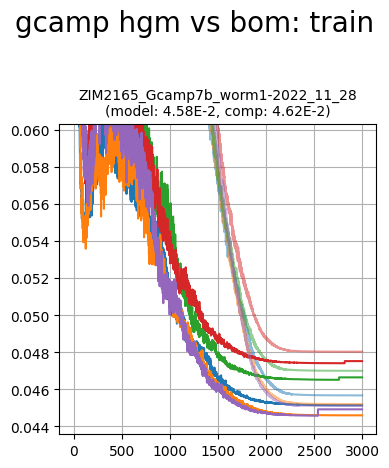

In [51]:
if gcamp:
	plot_utils.plot_losses_splits(filenames_gcamp,
								  hgms_losses_train_gcamp, boms_losses_train_gcamp,
								  title='gcamp hgm vs bom: train',
								  ylimits=0.01)

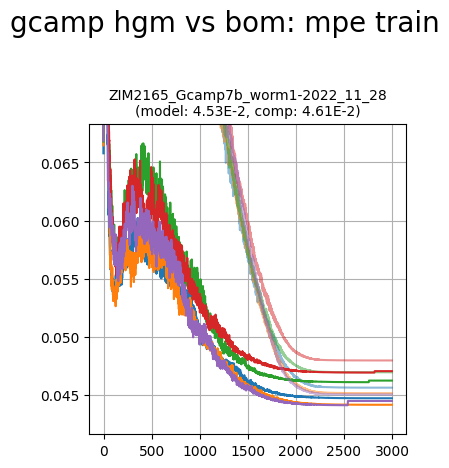

In [52]:
if gcamp:
	plot_utils.plot_losses_splits(filenames_gcamp,
								  hgms_mpe_losses_train_gcamp, boms_mpe_losses_train_gcamp,
								  title='gcamp hgm vs bom: mpe train',
								  ylimits=0.025)

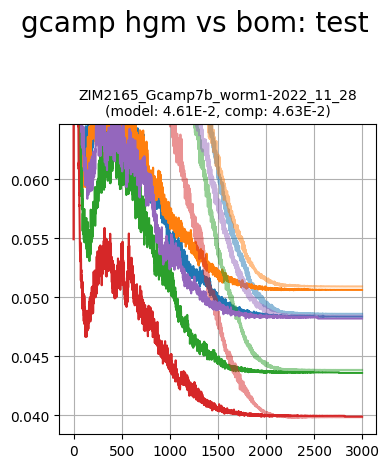

In [53]:
if gcamp:
	plot_utils.plot_losses_splits(filenames_gcamp,
								  hgms_losses_test_gcamp, boms_losses_test_gcamp,
								  title='gcamp hgm vs bom: test',
								  ylimits=0.015)

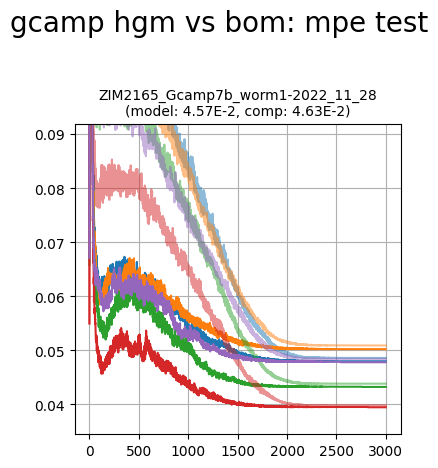

In [54]:
if gcamp:
	plot_utils.plot_losses_splits(filenames_gcamp,
								  hgms_mpe_losses_test_gcamp, boms_mpe_losses_test_gcamp,
								  title='gcamp hgm vs bom: mpe test',
								  ylimits=0.05)

### predict & score

In [55]:
if gcamp:
	splits_gcamp = [list(StratifiedKFold(n_splits=5, shuffle=False).split(np.zeros(traces_gcamp[i].shape[0]), discrete_states_gcamp[i][['REV']].values)) for i in range(len(file_ids_gcamp))]

In [56]:
if gcamp:
	boms_spn_man_rec_res_pres_gcamp = [[
		bom.score_fn(params, traces_gcamp[i].values[eval], eigenworms_gcamp[i].values[eval]) for params, (train, eval) in zip(boms_params_gcamp[i], splits_gcamp[i])
	] for i in range(len(file_ids_gcamp))]

	hgms_spn_man_rec_res_pres_gcamp = [[
		hgm.score_fn(params, traces_gcamp[i].values[eval], eigenworms_gcamp[i].values[eval]) for params, (train, eval) in zip(hgms_params_gcamp[i], splits_gcamp[i])
	] for i in range(len(file_ids_gcamp))]

	(boms_spn_gcamp,
	 boms_man_gcamp,
	 boms_rec_gcamp,
	 boms_res_gcamp,
	 boms_pres_gcamp) = seperate_predictions(file_ids_gcamp, [trace.columns for trace in traces_gcamp], boms_spn_man_rec_res_pres_gcamp)

	(hgms_spn_gcamp,
	 hgms_man_gcamp,
	 hgms_rec_gcamp,
	 hgms_res_gcamp,
	 hgms_pres_gcamp) = seperate_predictions(file_ids_gcamp, [trace.columns for trace in traces_gcamp], hgms_spn_man_rec_res_pres_gcamp)

### performance

In [57]:
if gcamp:
	neuron_scores_gcamp = assemble(boms_spn_gcamp, hgms_spn_gcamp)

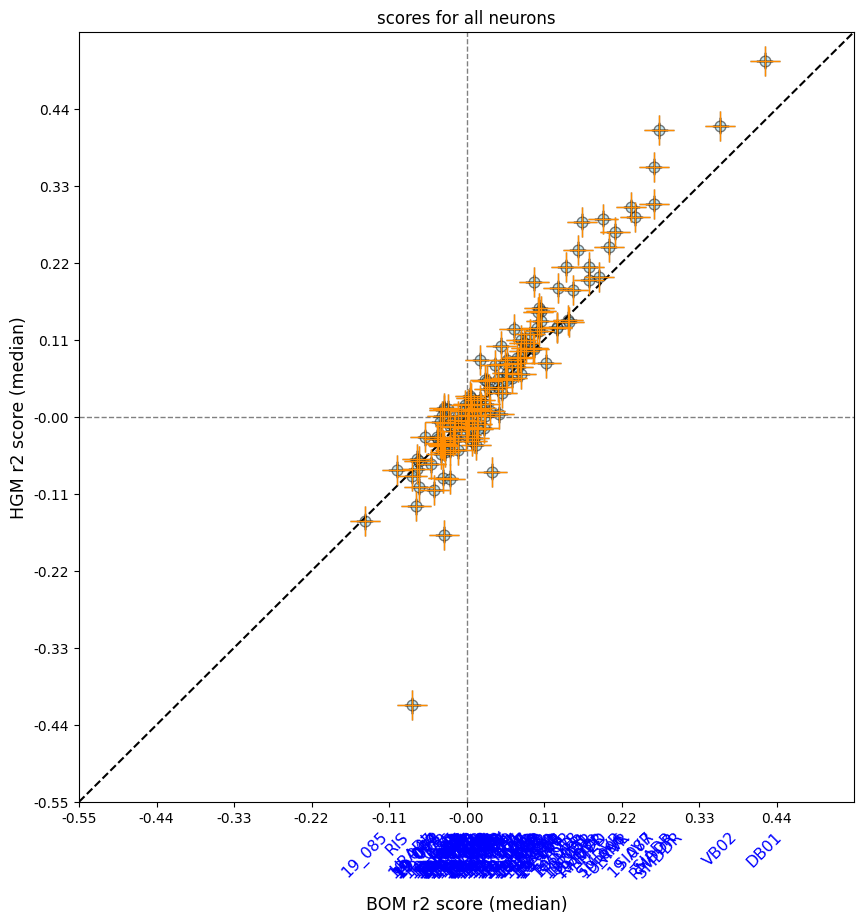

In [58]:
if gcamp:
	plot_utils.plot_performance_plot(
		neuron_scores_gcamp, None,
		title='scores for all neurons', limits=(-0.55, 0.55, -0.55, 0.55), force_medians=True
	)

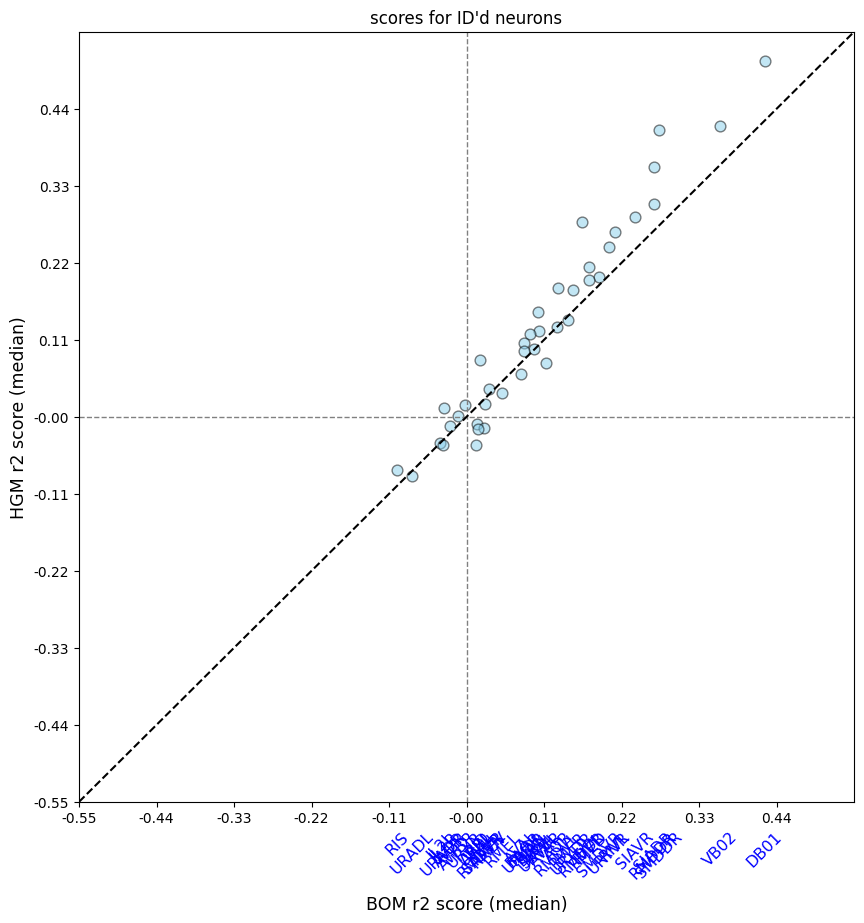

In [59]:
if gcamp:
	plot_utils.plot_performance_plot(
		{key: neuron_scores_gcamp[key] for key in neuron_scores_gcamp.keys() if not key[0].isdigit()}, None,
		title='scores for ID\'d neurons', limits=(-0.55, 0.55, -0.55, 0.55)
	)

### manifold

In [60]:
if gcamp:
	boms_spn_man_rec_res_pres_gcamp = [[
		bom.score_fn(params, traces_gcamp[i].values, eigenworms_gcamp[i].values) for params in boms_params_gcamp[i]
	] for i in range(len(file_ids_gcamp))]

	hgms_spn_man_rec_res_pres_gcamp = [[
		hgm.score_fn(params, traces_gcamp[i].values, eigenworms_gcamp[i].values) for params in hgms_params_gcamp[i]
	] for i in range(len(file_ids_gcamp))]

	(boms_spn_gcamp_full,
	 boms_man_gcamp_full,
	 boms_rec_gcamp_full,
	 boms_res_gcamp_full,
	 boms_pres_gcamp_full) = seperate_predictions(file_ids_gcamp, [trace.columns for trace in traces_gcamp], boms_spn_man_rec_res_pres_gcamp)

	(hgms_spn_gcamp_full,
	 hgms_man_gcamp_full,
	 hgms_rec_gcamp_full,
	 hgms_res_gcamp_full,
	 hgms_pres_gcamp_full) = seperate_predictions(file_ids_gcamp, [trace.columns for trace in traces_gcamp], hgms_spn_man_rec_res_pres_gcamp)

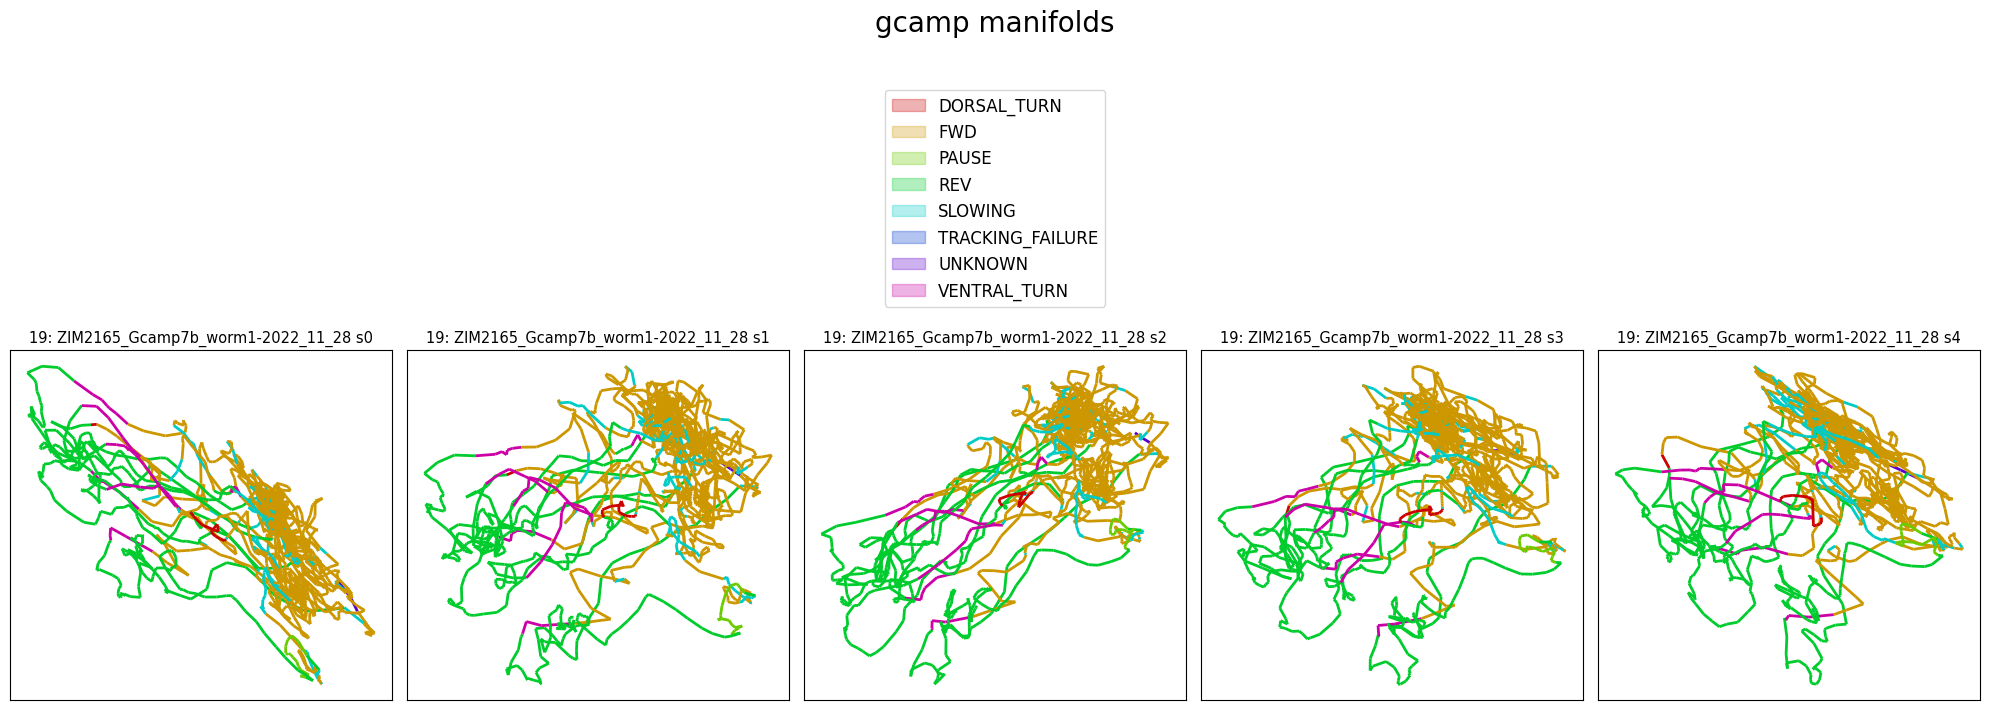

In [61]:
if gcamp and manual_hyperparameters['dimensions'] > 1:
	splits = 5
	plot_utils.plot_manifolds([f'{str(plot_id_gcamp)}: {filenames_gcamp[plot_idx_gcamp]} s{s}' for s in range(splits)],
							  [hgms_man_gcamp_full[plot_idx_gcamp][s] for s in range(splits)],
							  [discrete_states_gcamp[plot_idx_gcamp] for s in range(splits)],
							  None, None,
							  title='gcamp manifolds', plots_per_row=splits, top_space=3.5,
							  save_path=None)

### traces

In [62]:
if gcamp:
	_, _, traces_cca_rec_gcamp, _, _, _, _, _ = train_utils.get_manifolds_cca(traces_gcamp, discrete_states_gcamp, n_cv=manual_hyperparameters['dimensions'], n_pc=0)
	traces_cca_res_gcamp = [pd.DataFrame(data=trace_gcamp.values - trace_cca_rec_gcamp.values, columns=trace_gcamp.columns) for trace_gcamp, trace_cca_rec_gcamp in zip(traces_gcamp, traces_cca_rec_gcamp)]

In [63]:
if gcamp:
	plot_n = 5
	best_n_hgm_gcamp = [item[0] for item in neuron_scores_gcamp.items() if not item[0][0].isdigit()][:plot_n]
	best_n_hgm_gcamp_plot = [n for n in best_n_hgm_gcamp if n in traces_gcamp[plot_idx_gcamp].columns]

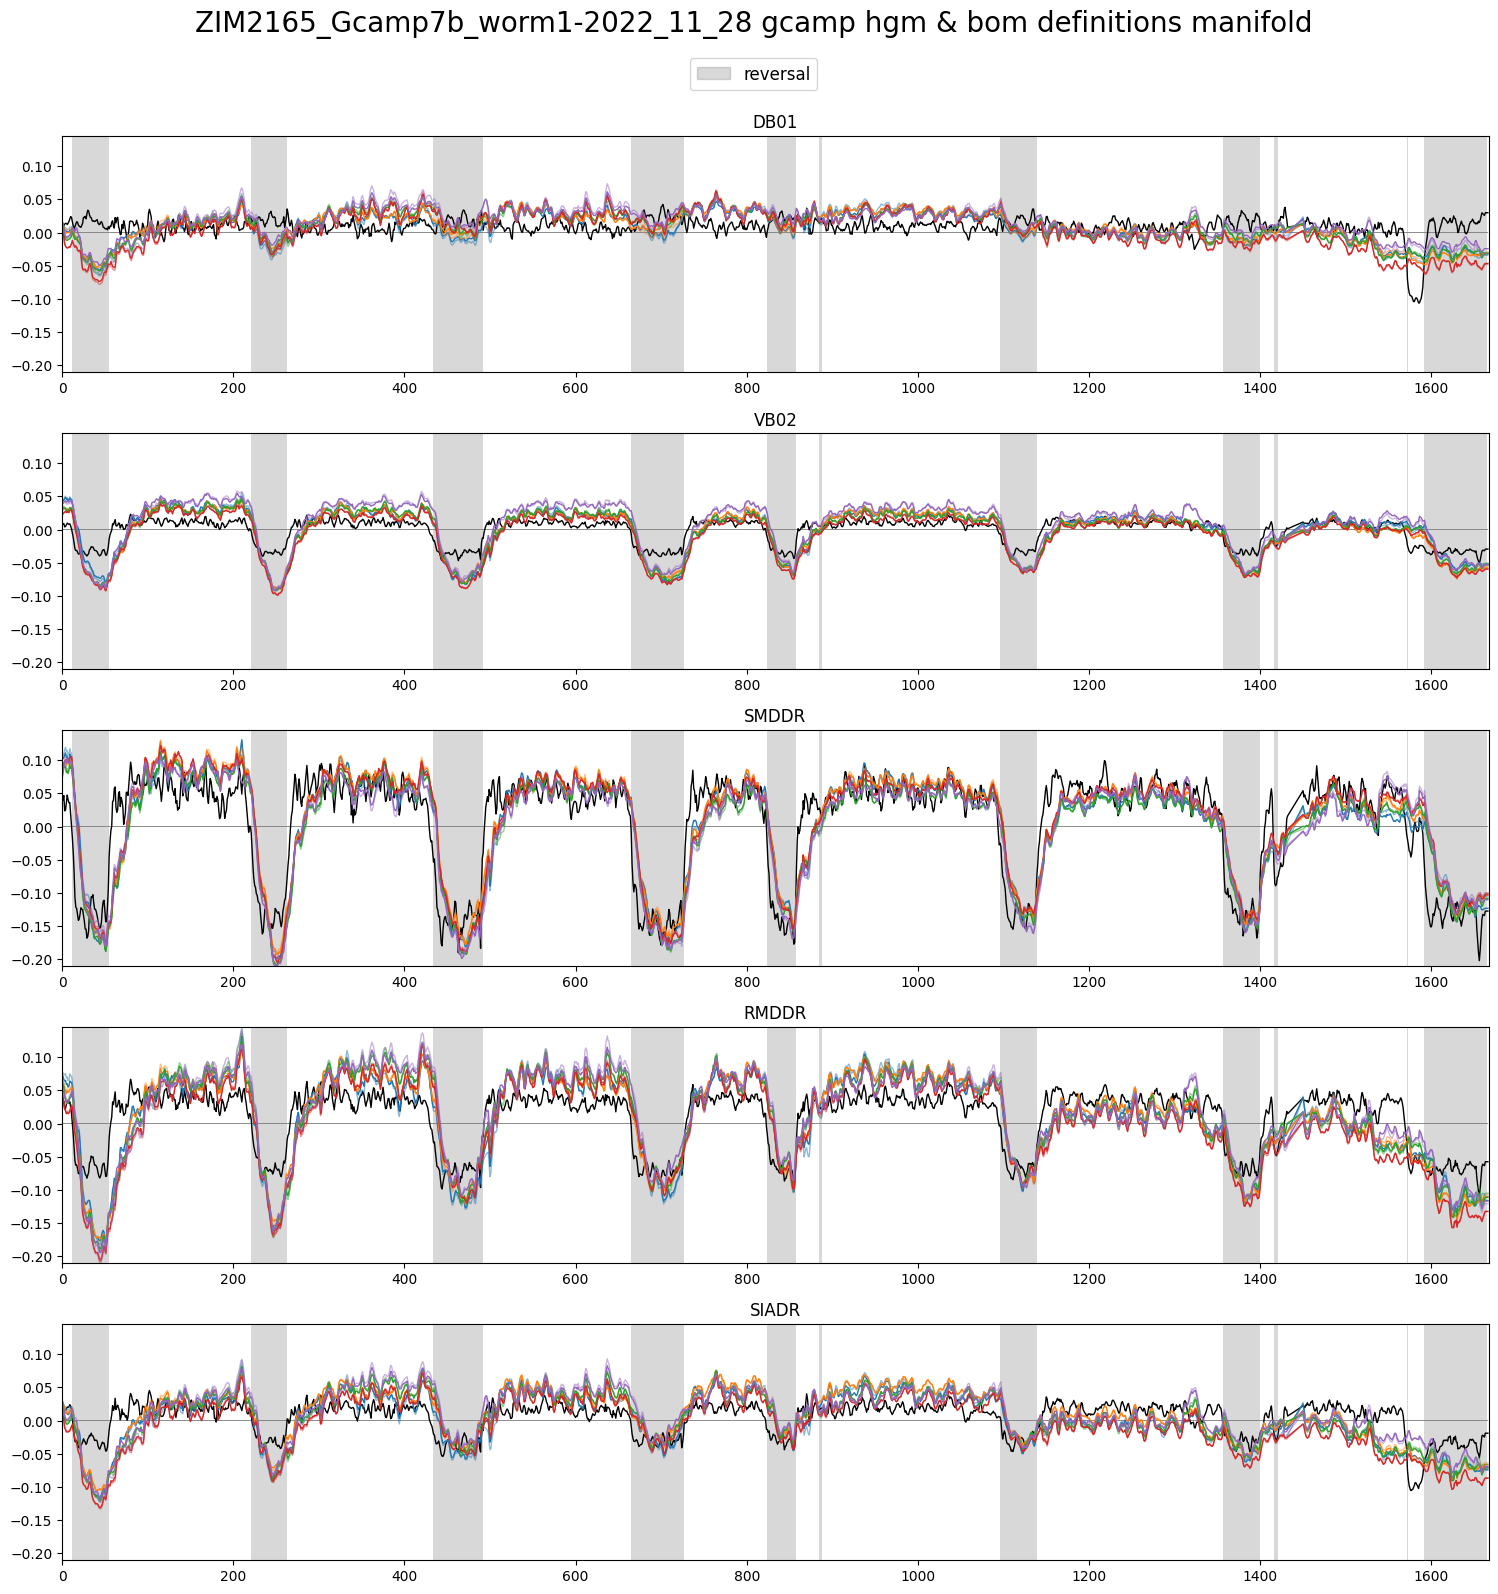

In [64]:
if gcamp:
	splits = 5
	plot_utils.plot_traces_splits(
		[hgms_rec_gcamp_full[plot_idx_gcamp][i][best_n_hgm_gcamp_plot] for i in range(splits)],
		[boms_rec_gcamp_full[plot_idx_gcamp][i][best_n_hgm_gcamp_plot] for i in range(splits)],
		traces_cca_rec_gcamp[plot_idx_gcamp][best_n_hgm_gcamp_plot],
		discrete_states_gcamp[plot_idx_gcamp][['REV']], label='reversal',
		title=f'{filenames_gcamp[plot_idx_gcamp]} gcamp hgm & bom definitions manifold', ylimits=None, plots_per_row=1,
		save_path=None)  #'../../out/plots/GCAMP_MAN'

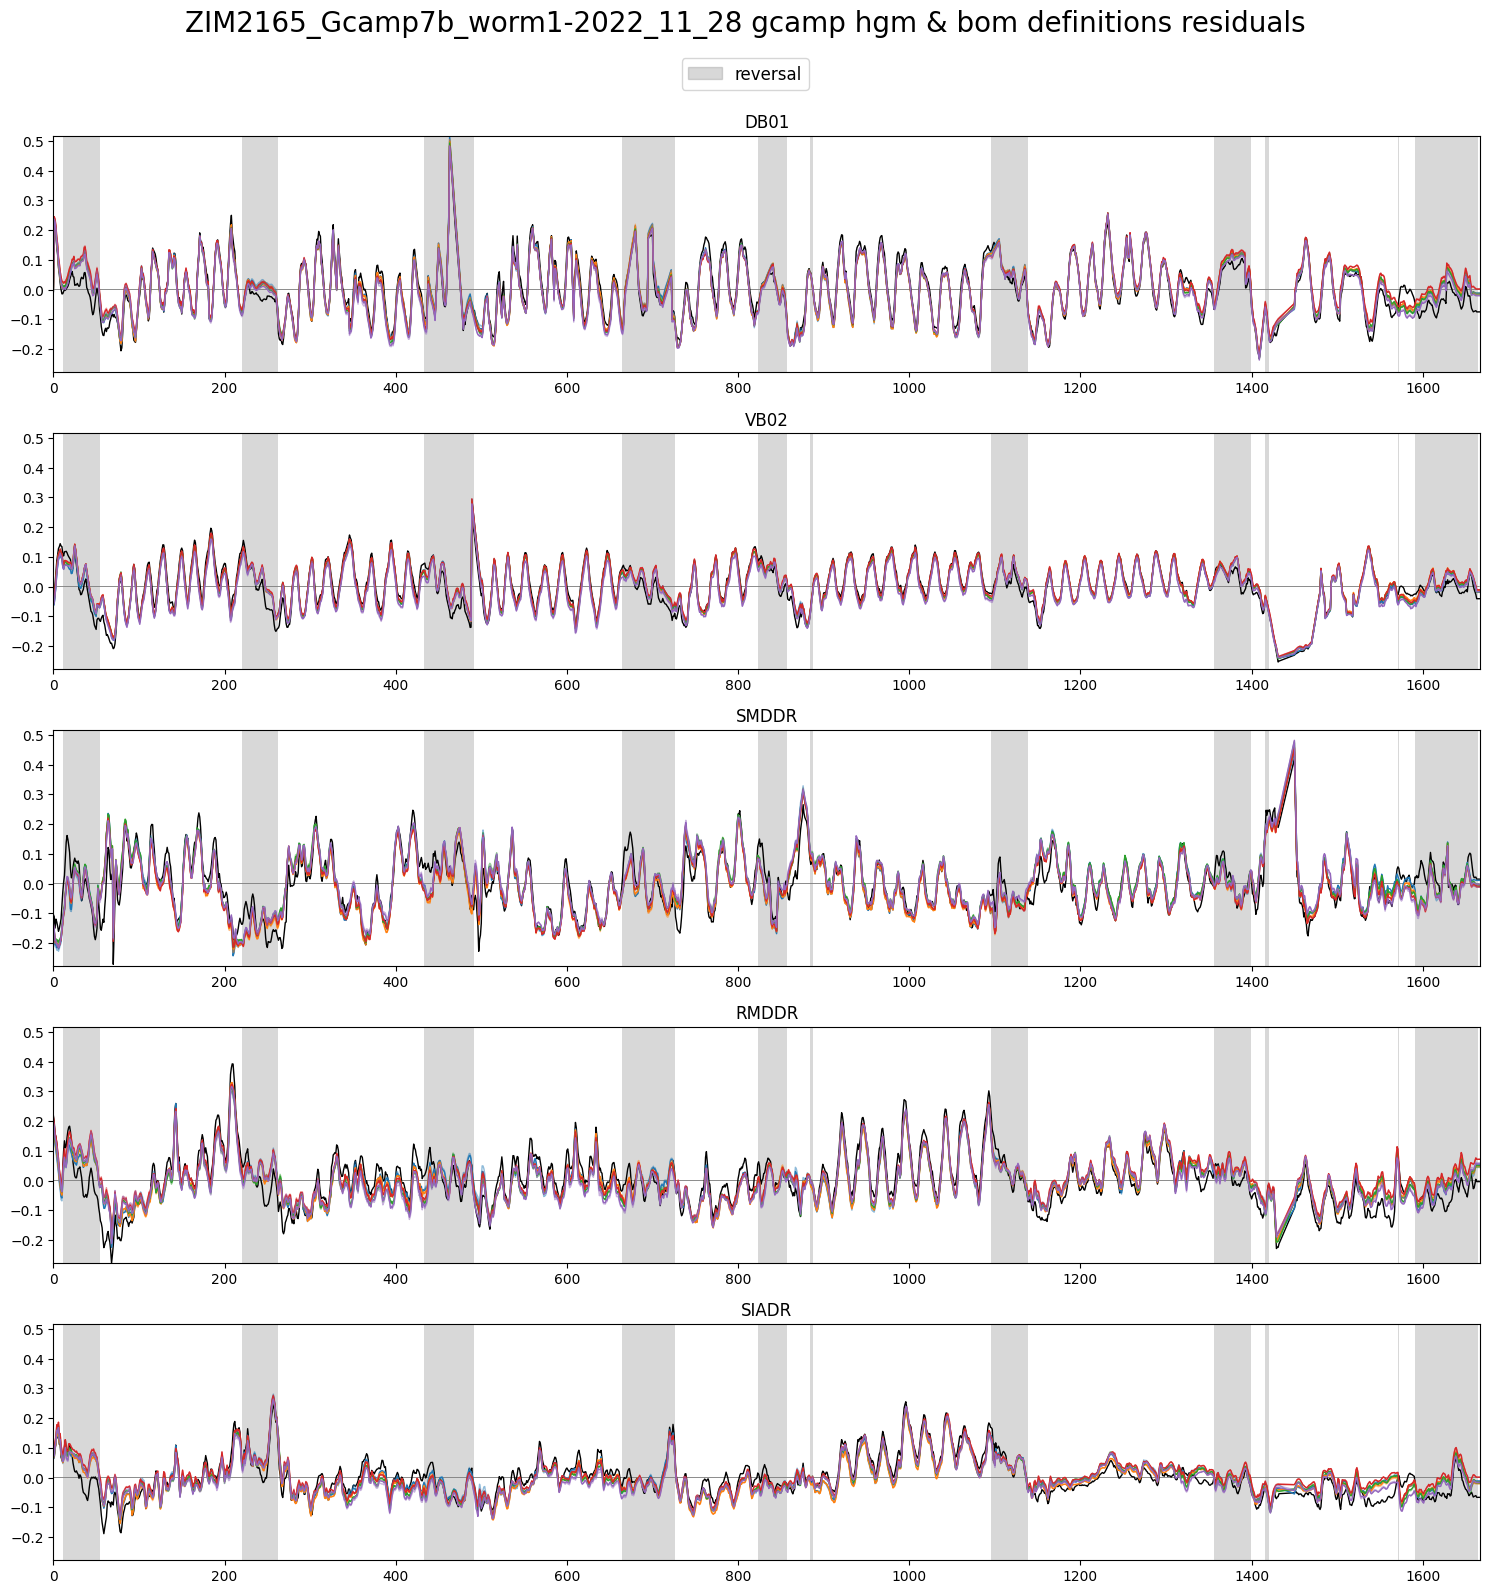

In [65]:
if gcamp:
	splits = 5
	plot_utils.plot_traces_splits(
		[hgms_res_gcamp_full[plot_idx_gcamp][i][best_n_hgm_gcamp_plot] for i in range(splits)],
		[boms_res_gcamp_full[plot_idx_gcamp][i][best_n_hgm_gcamp_plot] for i in range(splits)],
		traces_cca_res_gcamp[plot_idx_gcamp][best_n_hgm_gcamp_plot],
		discrete_states_gcamp[plot_idx_gcamp][['REV']], label='reversal',
		title=f'{filenames_gcamp[plot_idx_gcamp]} gcamp hgm & bom definitions residuals', ylimits=None, plots_per_row=1,
		save_path=None)  #'../../out/plots/GCAMP_MAN'

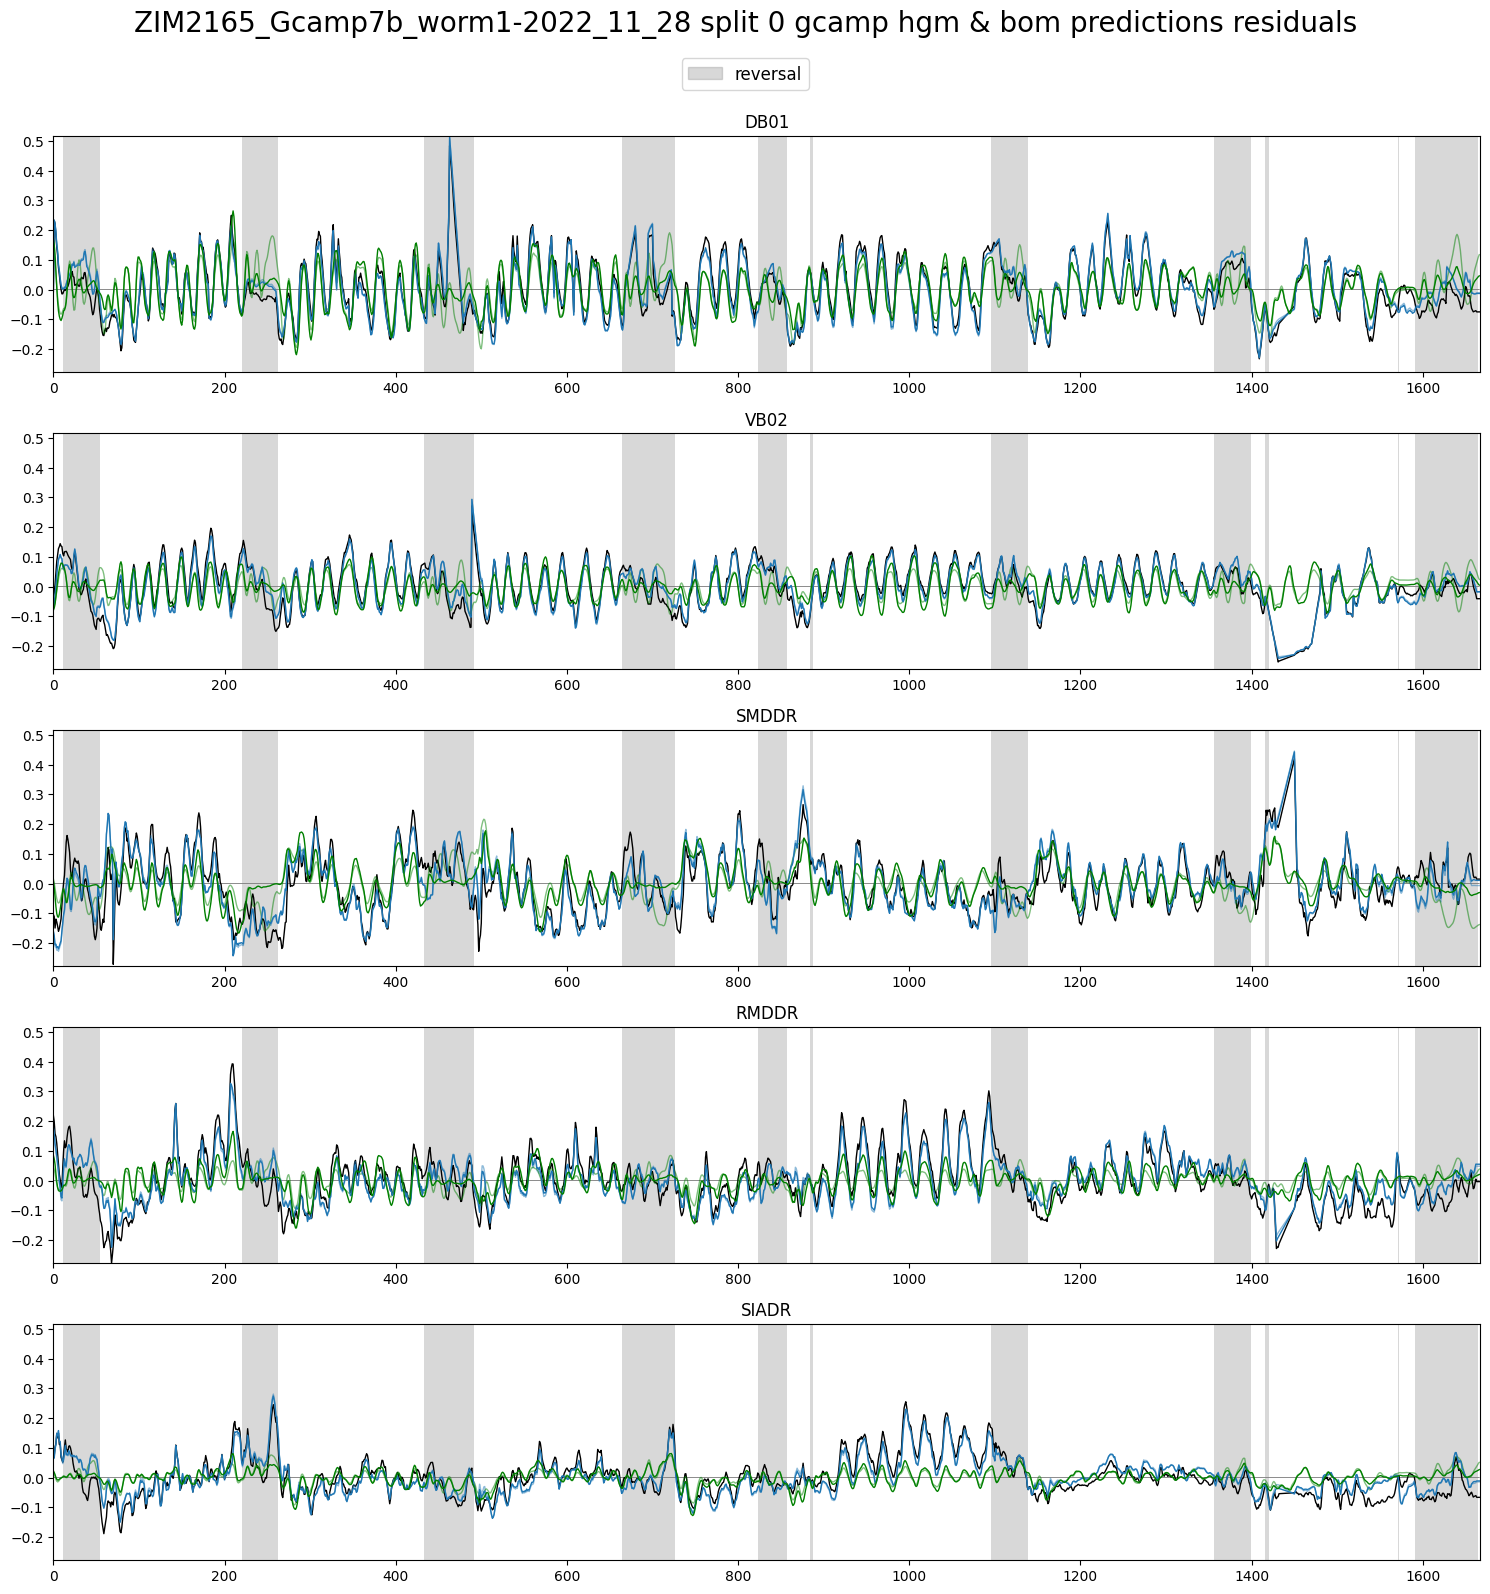

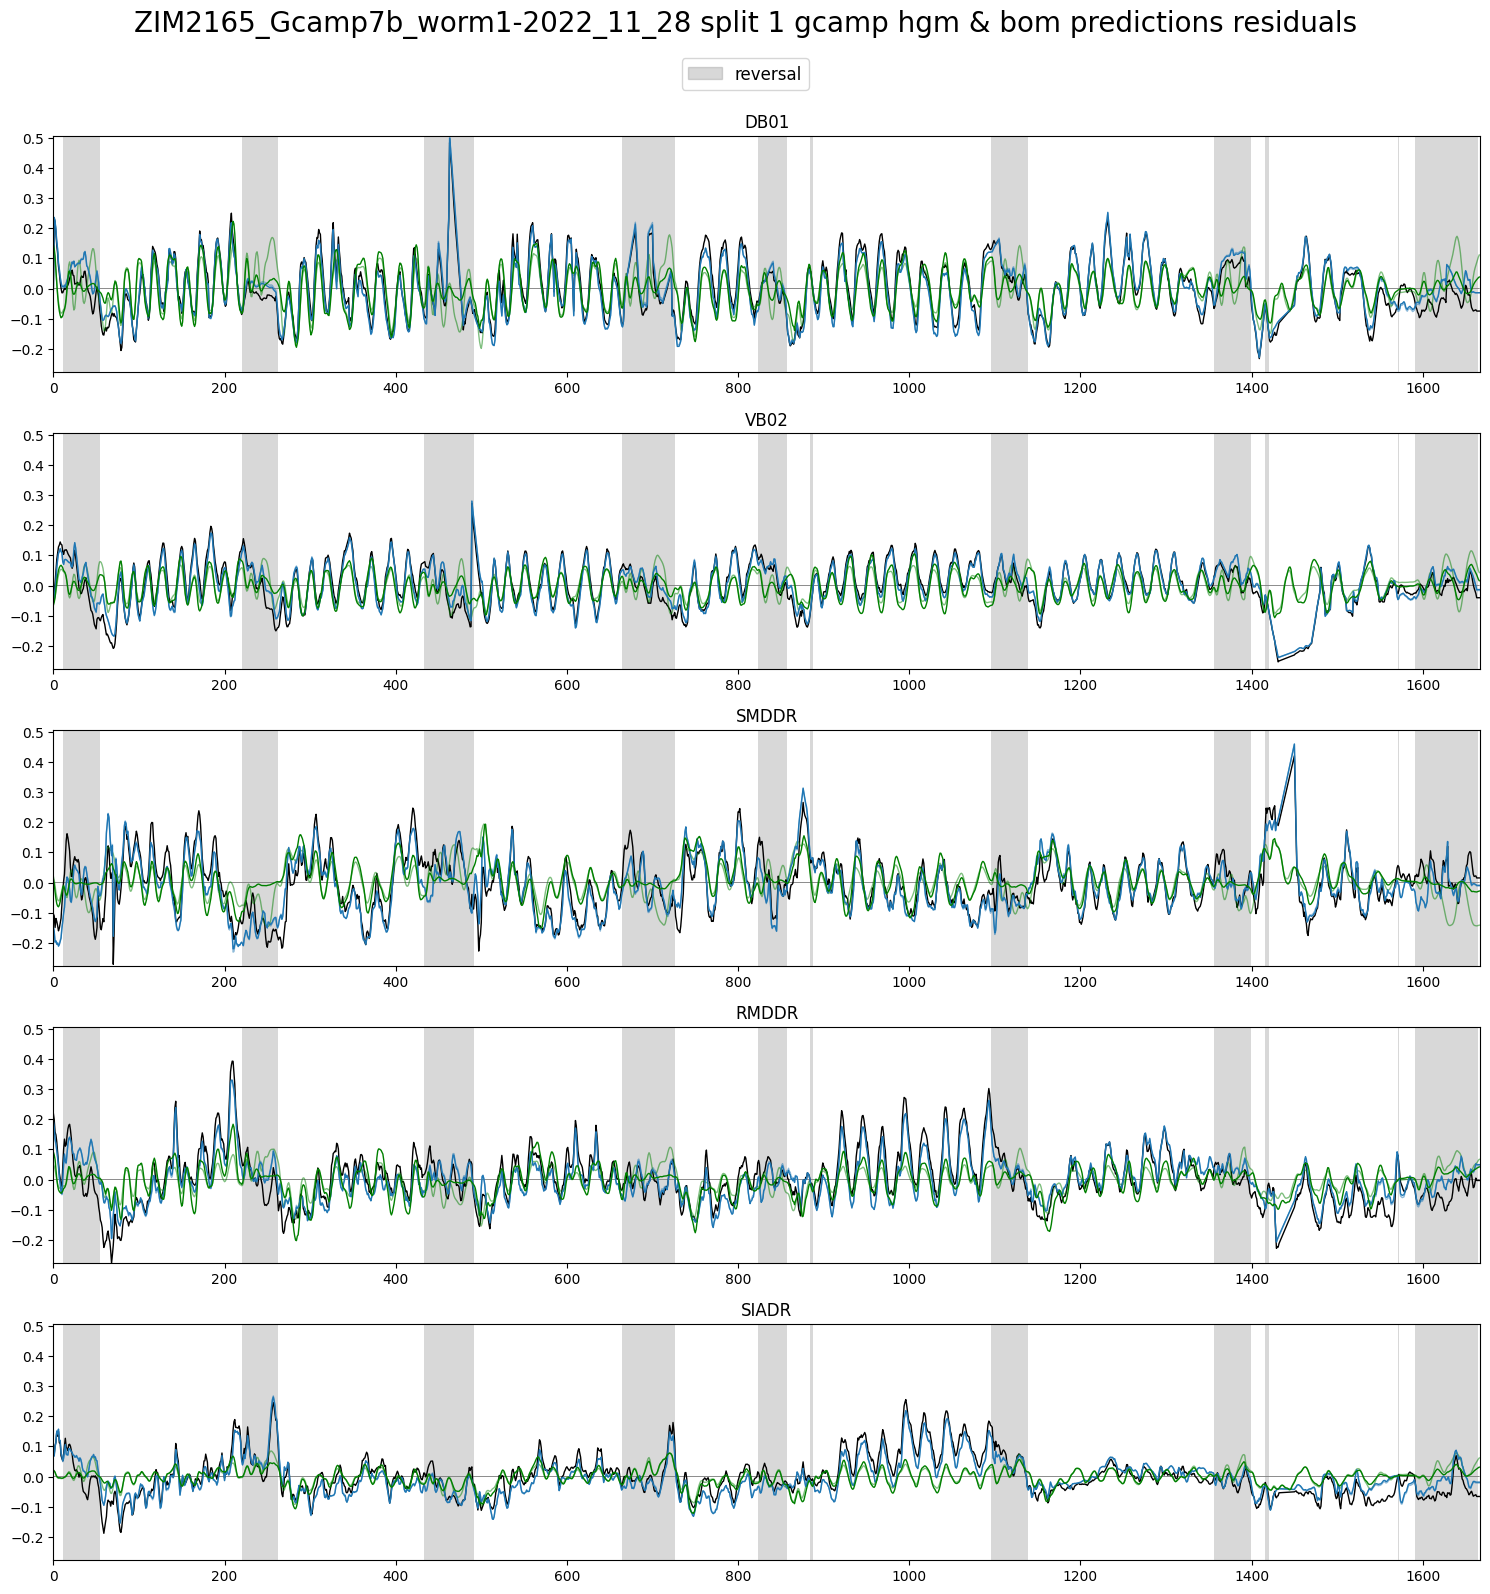

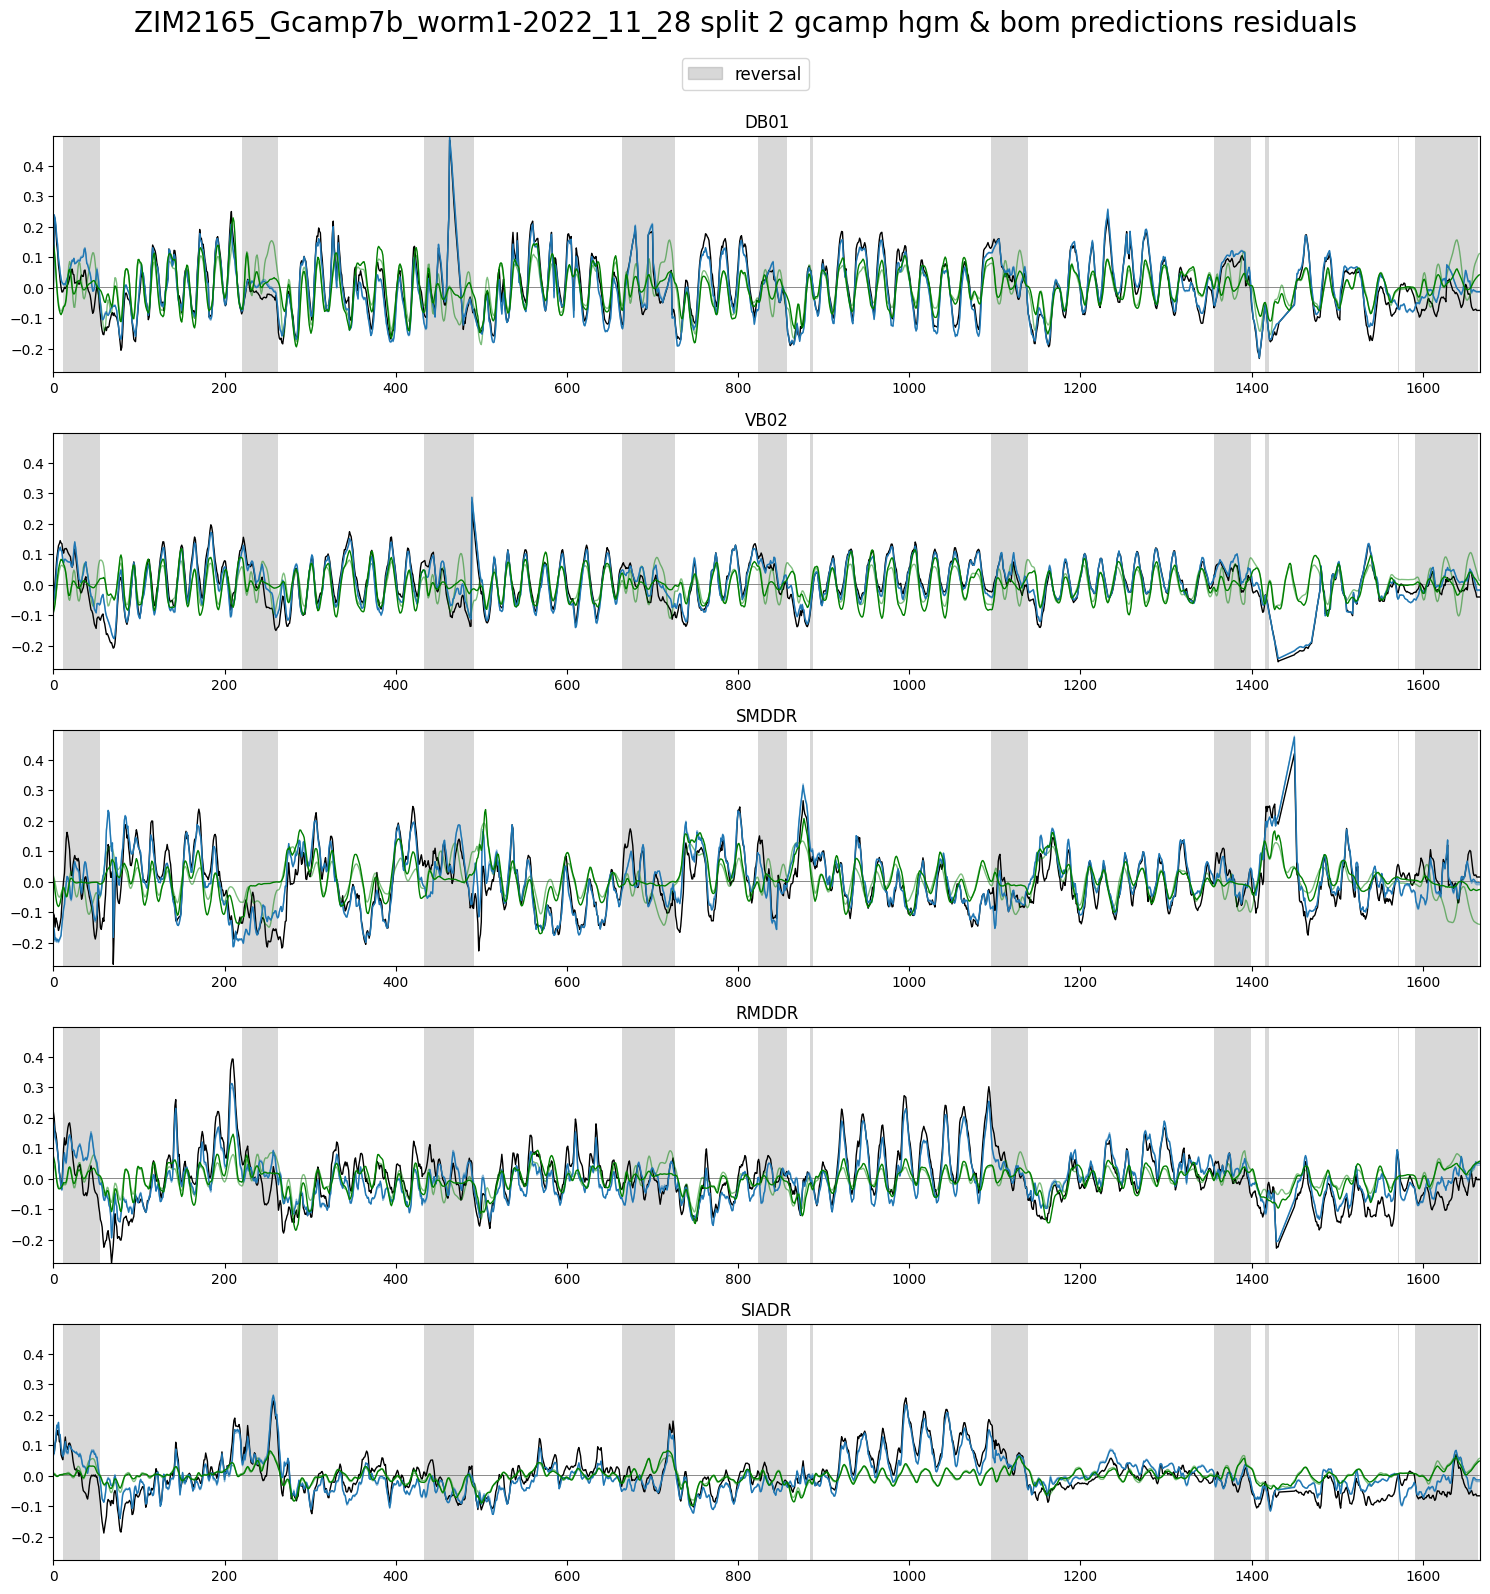

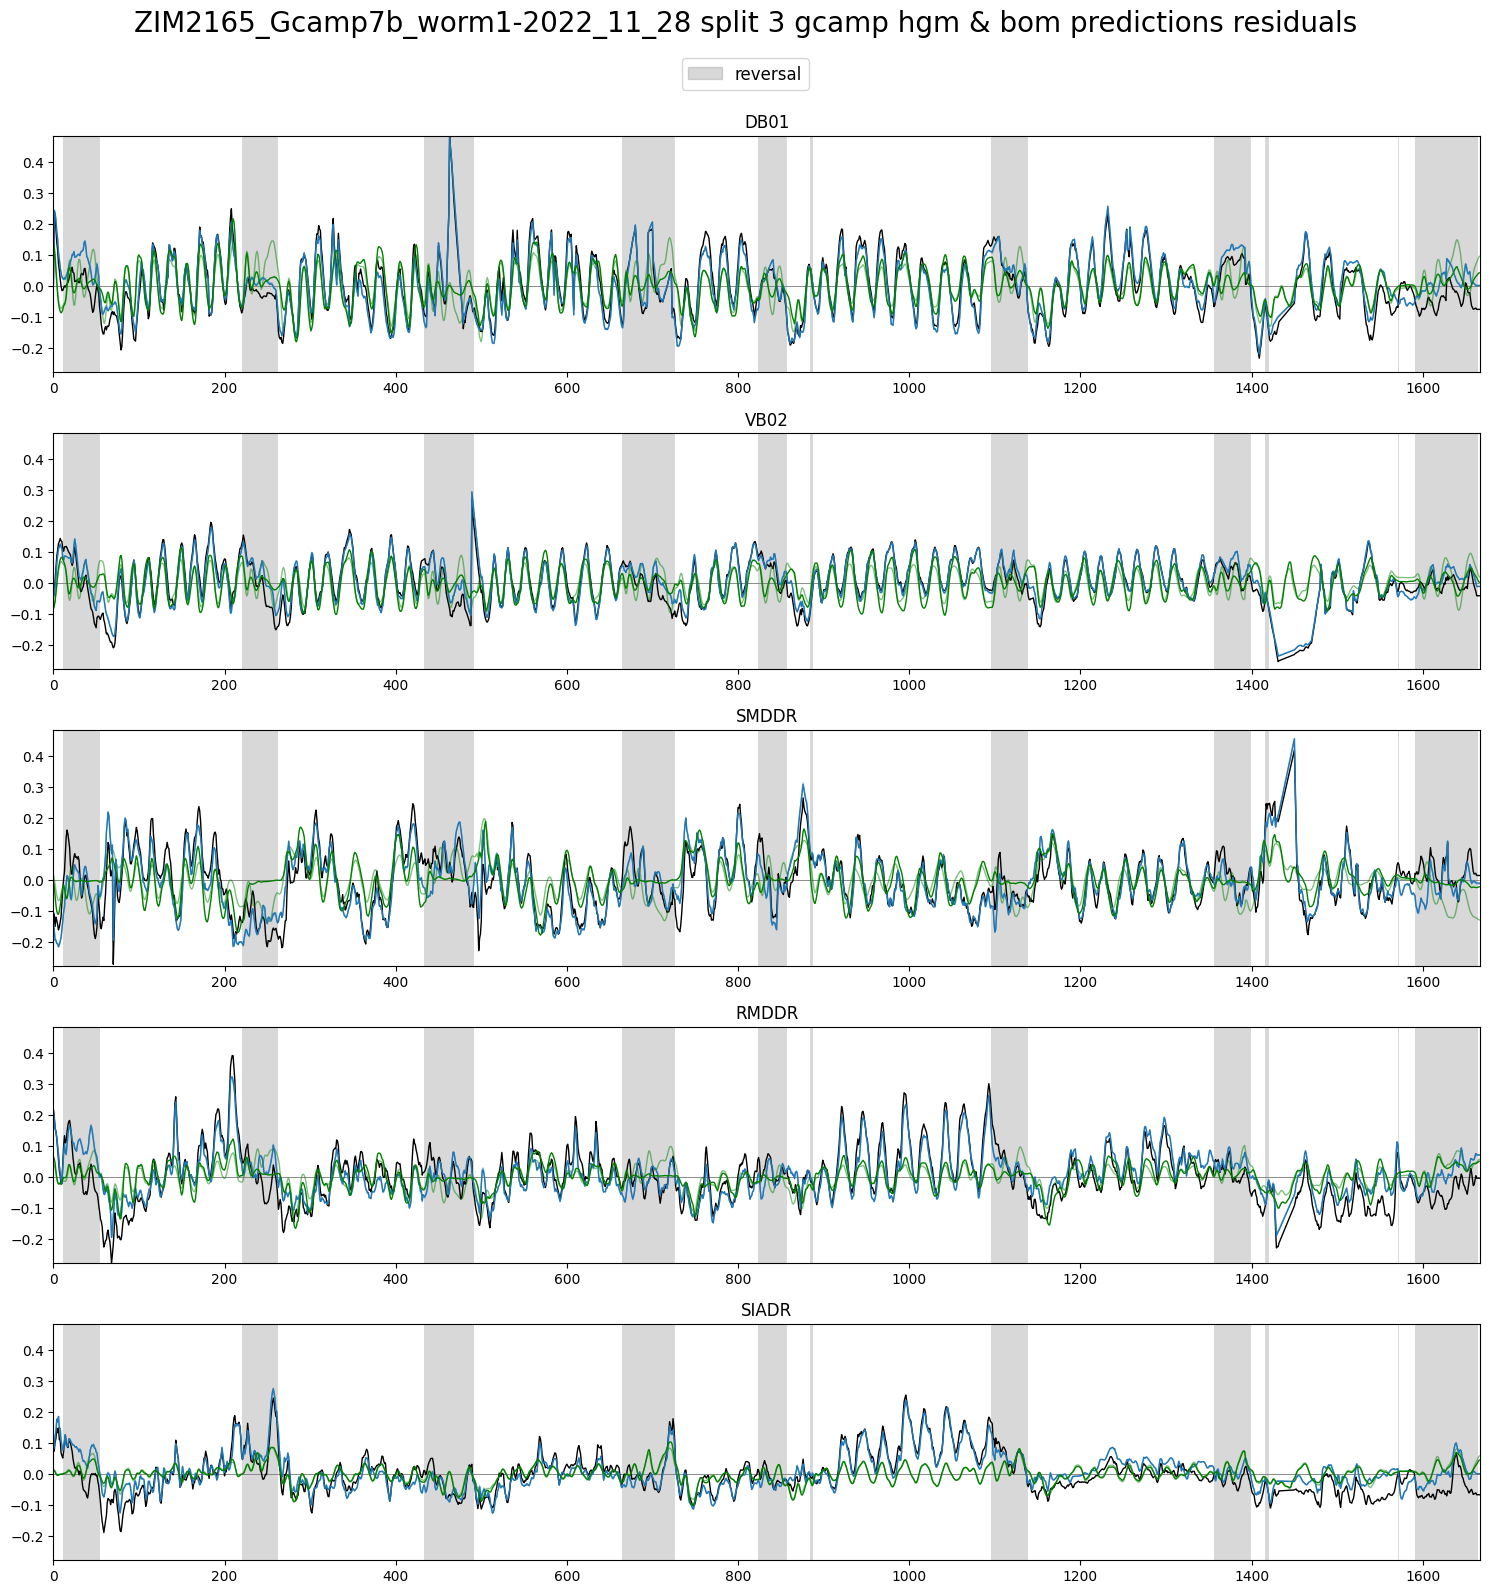

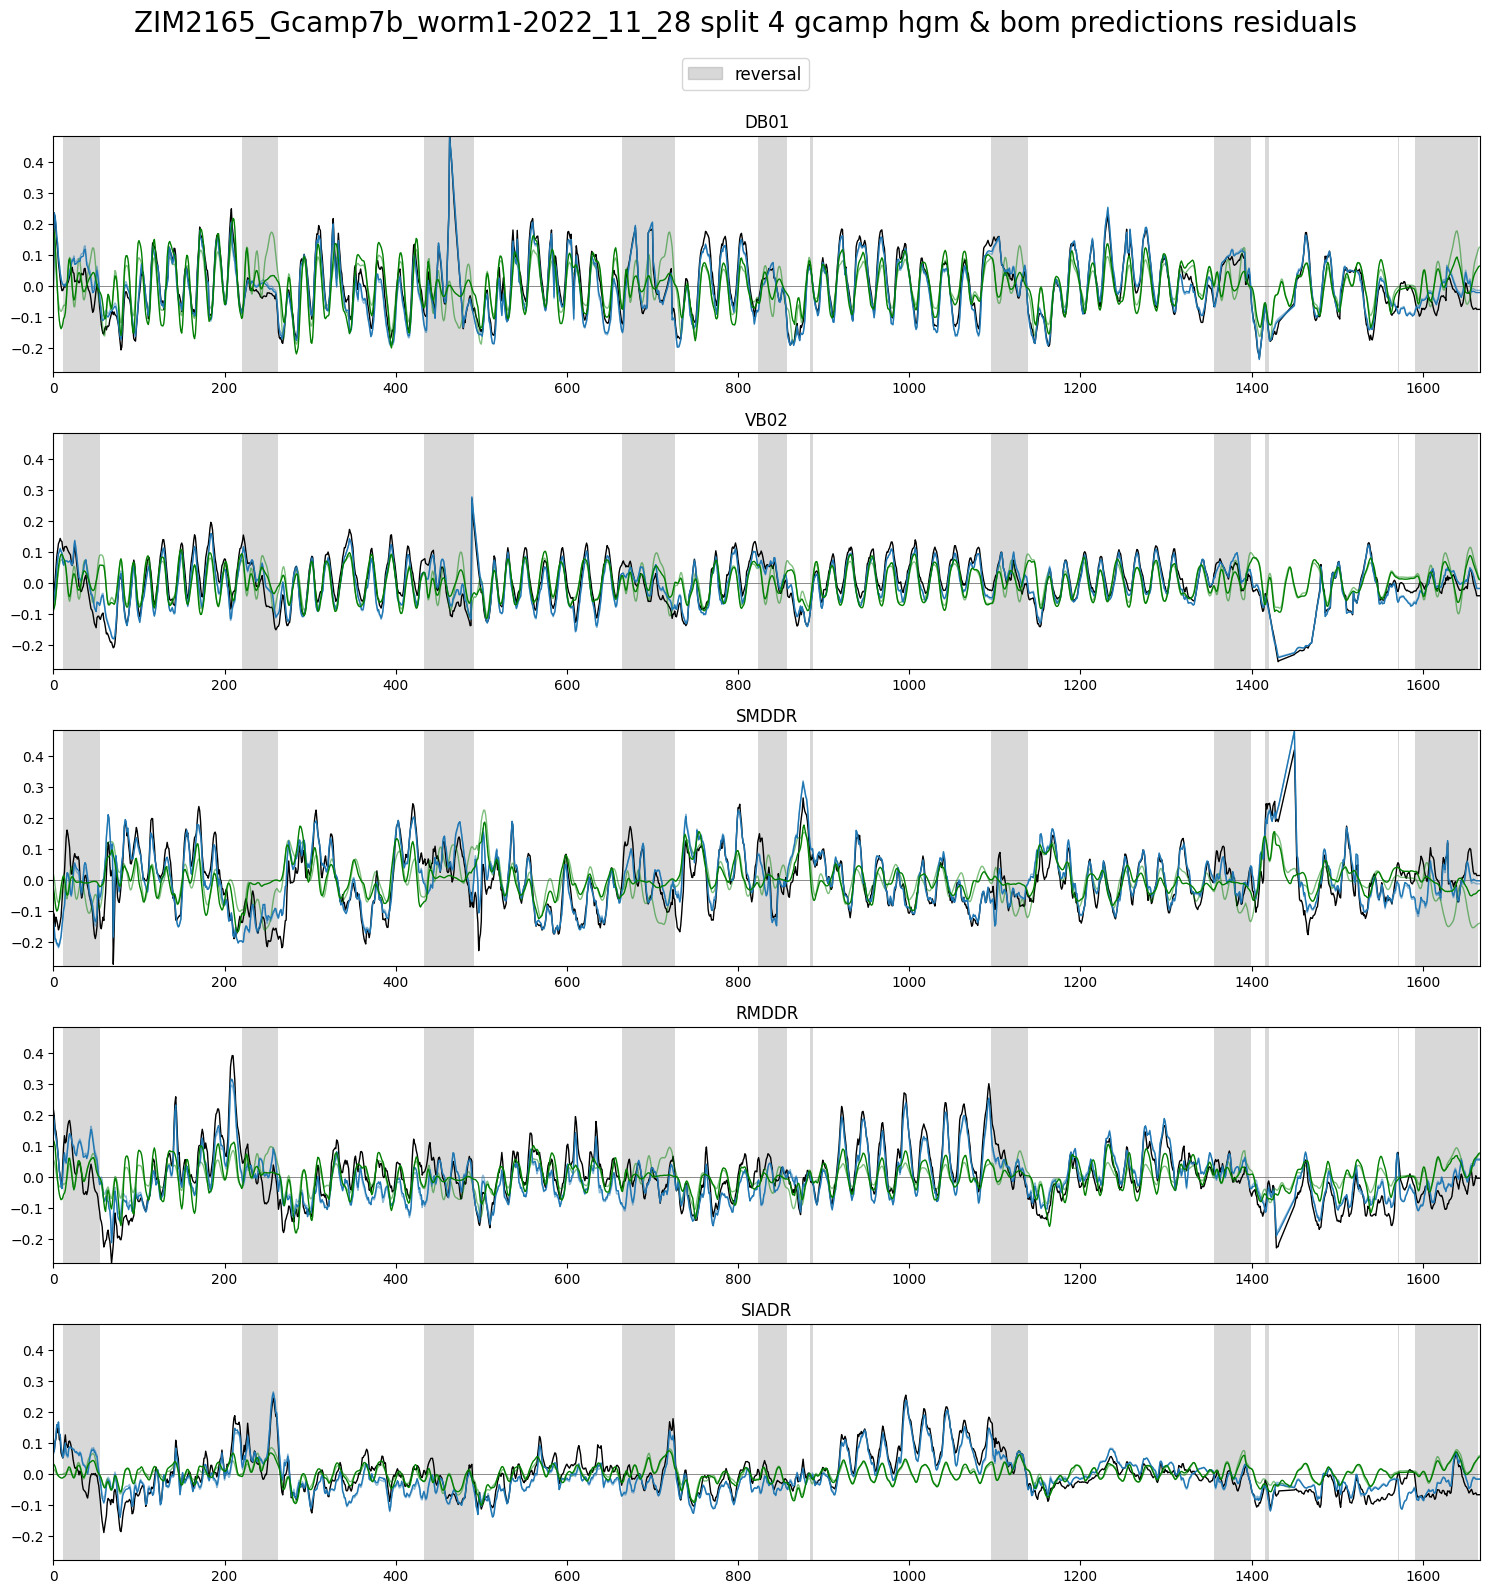

In [66]:
if gcamp:
	splits = 5
	for i in range(splits):
		plot_utils.plot_traces_splits_pairs(
			[hgms_res_gcamp_full[plot_idx_gcamp][i][best_n_hgm_gcamp_plot],
			 hgms_pres_gcamp_full[plot_idx_gcamp][i][best_n_hgm_gcamp_plot]],
			[boms_res_gcamp_full[plot_idx_gcamp][i][best_n_hgm_gcamp_plot],
			 boms_pres_gcamp_full[plot_idx_gcamp][i][best_n_hgm_gcamp_plot]],
			traces_cca_res_gcamp[plot_idx_gcamp][best_n_hgm_gcamp_plot],
			discrete_states_gcamp[plot_idx_gcamp][['REV']], label='reversal',
			title=f'{filenames_gcamp[plot_idx_gcamp]} split {i} gcamp hgm & bom predictions residuals', ylimits=None, plots_per_row=1,
			save_path=None)  #../../out/plots/f'GCAMP_PRES_S{i}'

In [67]:
# if gcamp:
# 	splits = 5
# 	plot_utils.plot_traces_splits(
# 		[hgms_rec_gcamp_full[plot_idx_gcamp][i][selection_n_traces_gcamp] for i in range(splits)],
# 		[boms_rec_gcamp_full[plot_idx_gcamp][i][selection_n_traces_gcamp] for i in range(splits)],
# 		traces_cca_rec_gcamp[plot_idx_gcamp][selection_n_traces_gcamp],
# 		discrete_states_gcamp[plot_idx_gcamp][['REV']], label='reversal',
# 		title=f'{filenames_gcamp[plot_idx_gcamp]} gcamp hgm & bom definitions manifold', ylimits=None, plots_per_row=1,
# 		save_path=None)  #'../../out/plots/GCAMP_MAN'

In [68]:
# if gcamp:
# 	splits = 5
# 	plot_utils.plot_traces_splits(
# 		[hgms_res_gcamp_full[plot_idx_gcamp][i][selection_n_traces_gcamp] for i in range(splits)],
# 		[boms_res_gcamp_full[plot_idx_gcamp][i][selection_n_traces_gcamp] for i in range(splits)],
# 		traces_cca_res_gcamp[plot_idx_gcamp][selection_n_traces_gcamp],
# 		discrete_states_gcamp[plot_idx_gcamp][['REV']], label='reversal',
# 		title=f'{filenames_gcamp[plot_idx_gcamp]} gcamp hgm & bom definitions residuals', ylimits=None, plots_per_row=1,
# 		save_path=None)  #'../../out/plots/GCAMP_MAN'

In [69]:
# if gcamp:
# 	splits = 5
# 	for i in range(splits):
# 		plot_utils.plot_traces_splits_pairs(
# 			[hgms_res_gcamp_full[plot_idx_gcamp][i][selection_n_traces_gcamp],
# 			 hgms_pres_gcamp_full[plot_idx_gcamp][i][selection_n_traces_gcamp]],
# 			[boms_res_gcamp_full[plot_idx_gcamp][i][selection_n_traces_gcamp],
# 			 boms_pres_gcamp_full[plot_idx_gcamp][i][selection_n_traces_gcamp]],
# 			traces_cca_res_gcamp[plot_idx_gcamp][selection_n_traces_gcamp],
# 			discrete_states_gcamp[plot_idx_gcamp][['REV']], label='reversal',
# 			title=f'{filenames_gcamp[plot_idx_gcamp]} split {i} gcamp hgm & bom predictions residuals', ylimits=None, plots_per_row=1,
# 			save_path=None)  #../../out/plots/f'GCAMP_PRES_S{i}'

# gfp

### predict & score

In [70]:
if gfp:
	splits_gfp = [list(StratifiedKFold(n_splits=5, shuffle=False).split(np.zeros(traces_gfp[i].shape[0]), discrete_states_gfp[i][['REV']].values)) for i in range(len(file_ids_gfp))]

In [71]:
if gfp:
	boms_spn_man_rec_res_pres_gfp = [[
		bom.score_fn(params, traces_gfp[i].values[eval], eigenworms_gfp[i].values[eval]) for params, (train, eval) in zip(boms_params_gfp[i], splits_gfp[i])
	] for i in range(len(file_ids_gfp))]

	hgms_spn_man_rec_res_pres_gfp = [[
		hgm.score_fn(params, traces_gfp[i].values[eval], eigenworms_gfp[i].values[eval]) for params, (train, eval) in zip(hgms_params_gfp[i], splits_gfp[i])
	] for i in range(len(file_ids_gfp))]

	(boms_spn_gfp,
	 boms_man_gfp,
	 boms_rec_gfp,
	 boms_res_gfp,
	 boms_pres_gfp) = seperate_predictions(file_ids_gfp, [trace.columns for trace in traces_gfp], boms_spn_man_rec_res_pres_gfp)

	(hgms_spn_gfp,
	 hgms_man_gfp,
	 hgms_rec_gfp,
	 hgms_res_gfp,
	 hgms_pres_gfp) = seperate_predictions(file_ids_gfp, [trace.columns for trace in traces_gfp], hgms_spn_man_rec_res_pres_gfp)

### performance

In [72]:
if gfp:
	neuron_scores_gfp = assemble(boms_spn_gfp, hgms_spn_gfp)

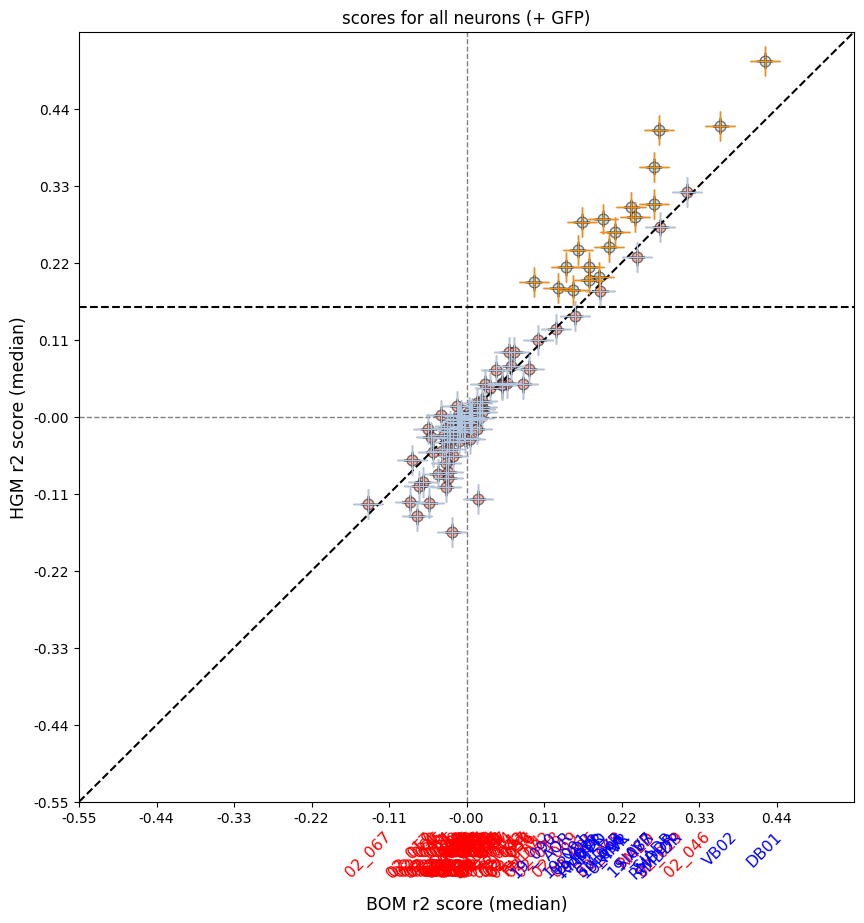

In [73]:
if gcamp and gfp:
	plot_utils.plot_performance_plot(
		neuron_scores_gcamp, neuron_scores_gfp,
		title='scores for all neurons (+ GFP)', limits=(-0.55, 0.55, -0.55, 0.55), force_medians=True
	)

In [74]:
if gcamp and gfp:
	threshold_hgm_gfp = np.quantile(np.concatenate([pair[1] for pair in neuron_scores_gfp.values()]), 0.95)

	significant_hgm_n_gcamp = list()
	for key in neuron_scores_gcamp.keys():
		scores_bom, scores_hgm = neuron_scores_gcamp[key]
		if len(scores_hgm.shape) == 0:
			scores_bom = scores_bom.reshape(1, 1)
			scores_hgm = scores_hgm.reshape(1, 1)
		y = np.median(scores_hgm)
		if y > threshold_hgm_gfp:
			significant_hgm_n_gcamp.append(key)

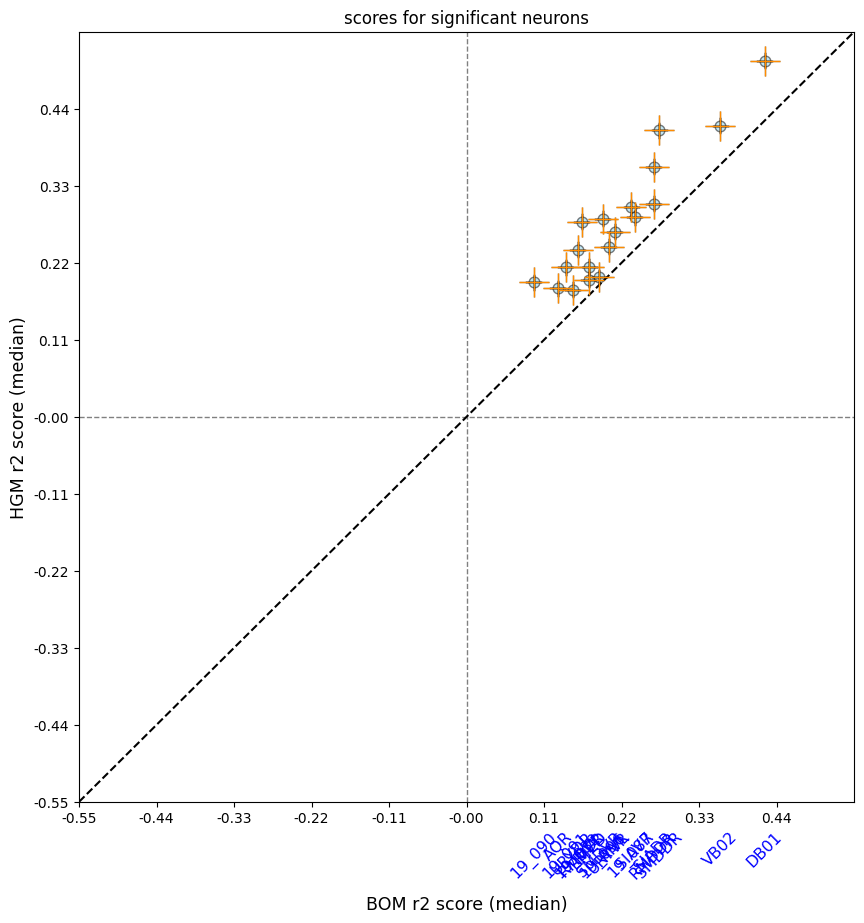

In [75]:
if gcamp and gfp:
	plot_utils.plot_performance_plot(
		{key: neuron_scores_gcamp[key] for key in significant_hgm_n_gcamp}, None,
		title='scores for significant neurons', limits=(-0.55, 0.55, -0.55, 0.55), force_medians=True
	)

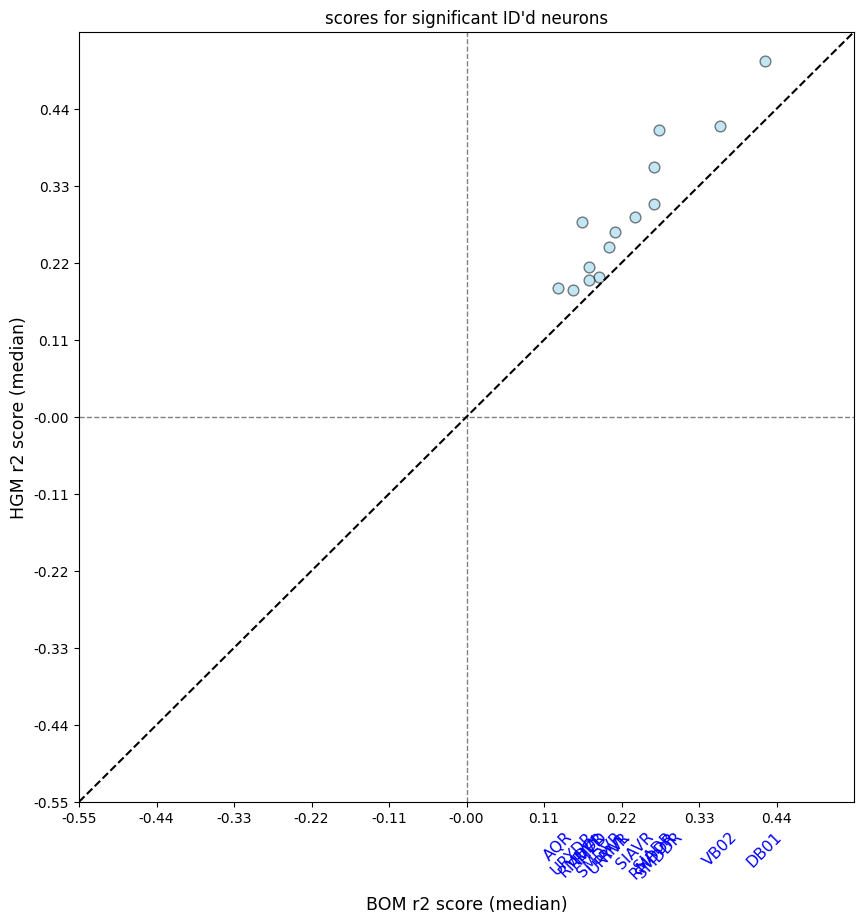

In [76]:
if gcamp and gfp:
	plot_utils.plot_performance_plot(
		{key: neuron_scores_gcamp[key] for key in significant_hgm_n_gcamp if not key[0].isdigit()}, None,
		title='scores for significant ID\'d neurons', limits=(-0.55, 0.55, -0.55, 0.55))

In [77]:
if gcamp and gfp:
	print('\n'.join([f'NEURON: {key},\tHGM: {np.median(val[1]):.4f}\tBOM: {np.median(val[0]):.4f}' for key, val in reversed(sorted(neuron_scores_gcamp.items(), key=lambda x: np.median(x[1][1]))) if key in significant_hgm_n_gcamp and not key[0].isdigit()]))

NEURON: DB01,	HGM: 0.5084	BOM: 0.4233
NEURON: VB02,	HGM: 0.4157	BOM: 0.3602
NEURON: SMDDR,	HGM: 0.4097	BOM: 0.2737
NEURON: RMDDR,	HGM: 0.3572	BOM: 0.2656
NEURON: SIADR,	HGM: 0.3044	BOM: 0.2660
NEURON: SIAVR,	HGM: 0.2850	BOM: 0.2391
NEURON: RMDDL,	HGM: 0.2788	BOM: 0.1634
NEURON: RIVL,	HGM: 0.2647	BOM: 0.2105
NEURON: URYVR,	HGM: 0.2432	BOM: 0.2019
NEURON: RIVR,	HGM: 0.2143	BOM: 0.1744
NEURON: SMDVR,	HGM: 0.1991	BOM: 0.1887
NEURON: RMED,	HGM: 0.1957	BOM: 0.1733
NEURON: AQR,	HGM: 0.1834	BOM: 0.1297
NEURON: URYDR,	HGM: 0.1815	BOM: 0.1508


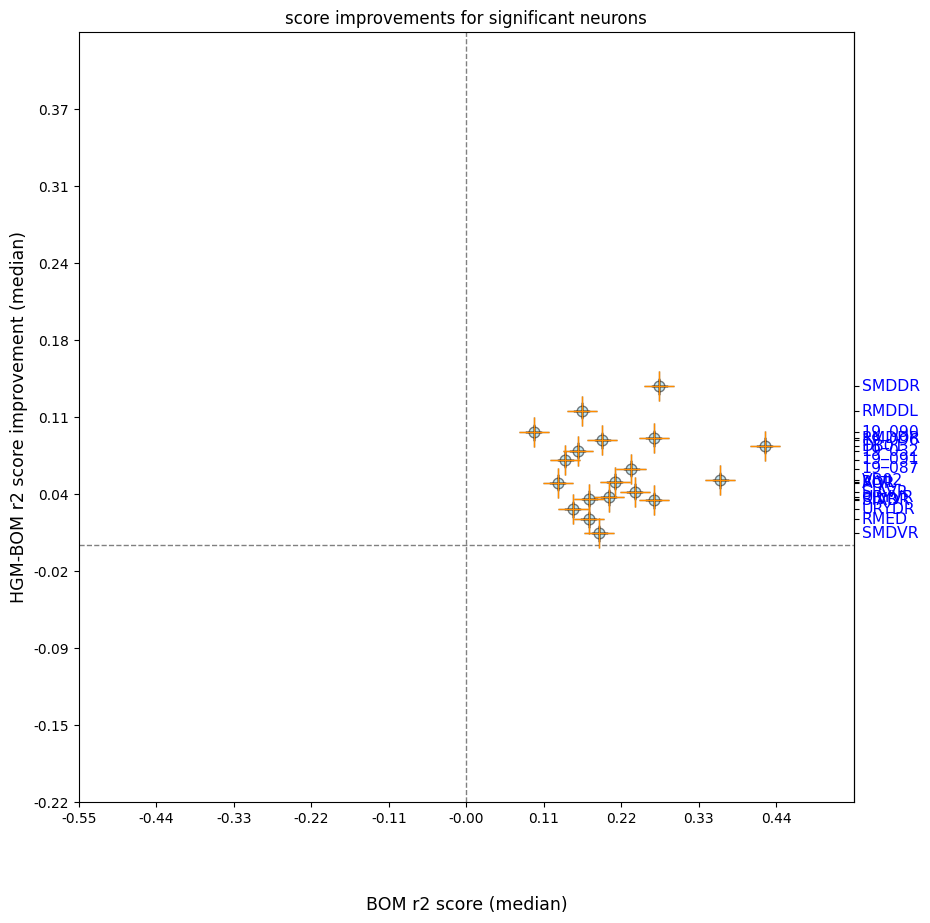

In [78]:
if gcamp and gfp:
	plot_utils.plot_improvement_plot(
		{key: neuron_scores_gcamp[key] for key in significant_hgm_n_gcamp},
		title='score improvements for significant neurons', limits=(-0.55, 0.55, -0.22, 0.44), force_medians=True)

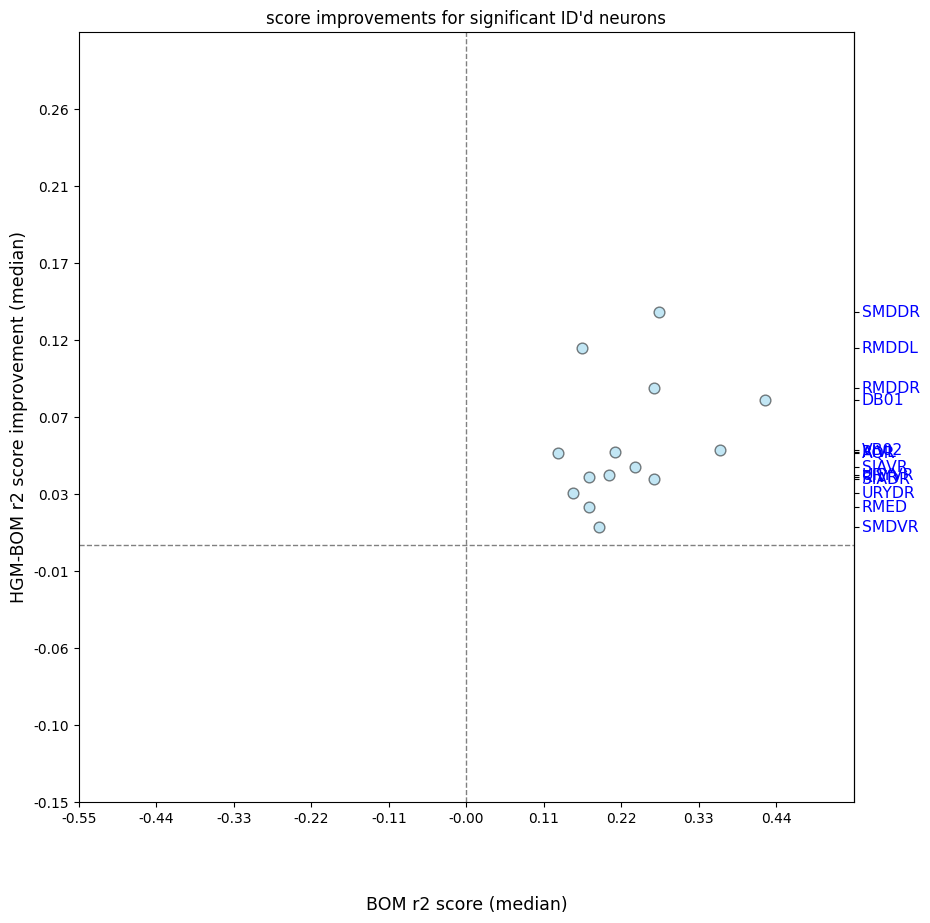

In [79]:
if gcamp and gfp:
	plot_utils.plot_improvement_plot(
		{key: neuron_scores_gcamp[key] for key in significant_hgm_n_gcamp if not key[0].isdigit()}, None,
		title='score improvements for significant ID\'d neurons', limits=(-0.55, 0.55, -0.15, 0.30))

In [80]:
if gcamp and gfp:
	print('\n'.join([f'NEURON: {key},\tIMPR: {np.median(val[1] - val[0]):.4f}' for key, val in reversed(sorted(neuron_scores_gcamp.items(), key=lambda x: np.median(x[1][1] - x[1][0]))) if key in significant_hgm_n_gcamp and not key[0].isdigit()]))

NEURON: SMDDR,	IMPR: 0.1360
NEURON: RMDDL,	IMPR: 0.1154
NEURON: RMDDR,	IMPR: 0.0916
NEURON: DB01,	IMPR: 0.0851
NEURON: VB02,	IMPR: 0.0555
NEURON: RIVL,	IMPR: 0.0543
NEURON: AQR,	IMPR: 0.0536
NEURON: SIAVR,	IMPR: 0.0459
NEURON: URYVR,	IMPR: 0.0413
NEURON: RIVR,	IMPR: 0.0399
NEURON: SIADR,	IMPR: 0.0385
NEURON: URYDR,	IMPR: 0.0306
NEURON: RMED,	IMPR: 0.0223
NEURON: SMDVR,	IMPR: 0.0104


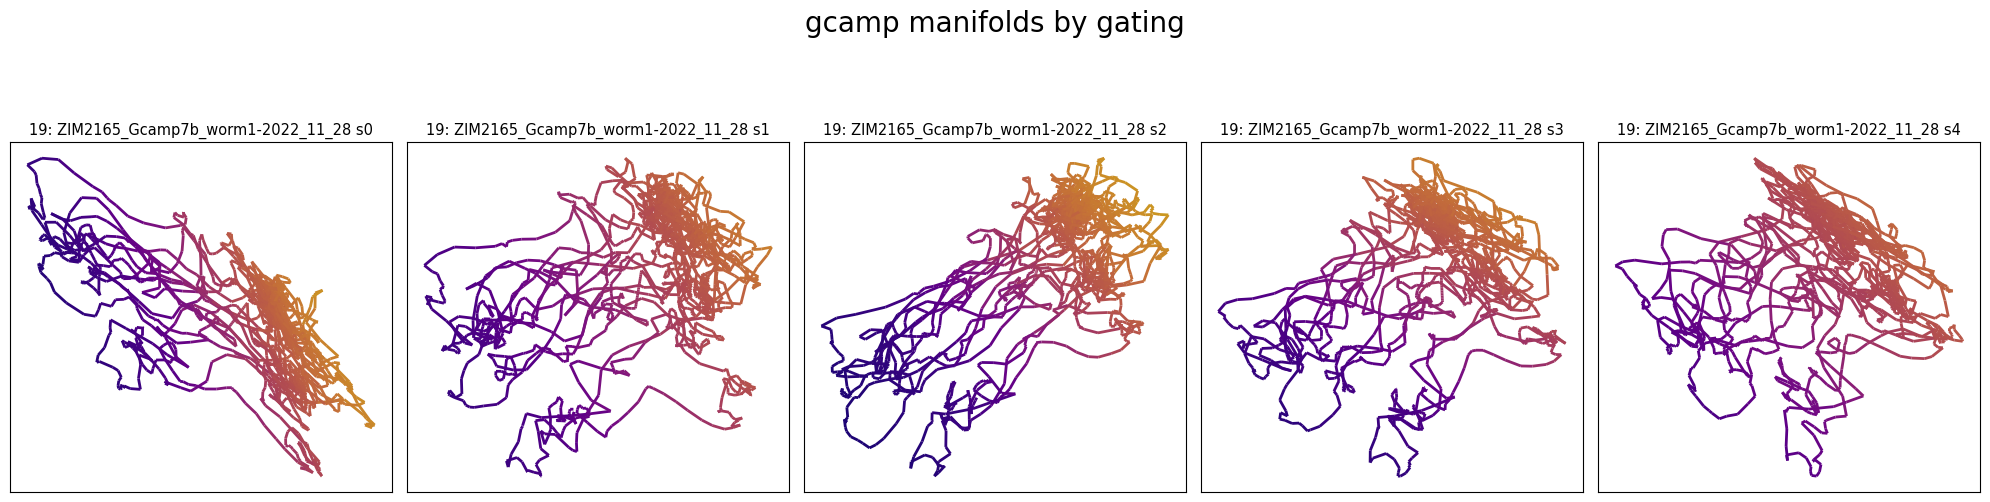

In [81]:
if gcamp and manual_hyperparameters['dimensions'] > 1:
	sigmoid = lambda x: 1 / (1 + np.exp(-x))

	neuron = 'VB02'
	neuron_id = traces_gcamp[plot_idx_gcamp].columns.get_loc(neuron)

	splits = 5
	sigmoid_terms = list()
	for split in range(splits):
		manifold_term = hgms_man_gcamp_full[plot_idx_gcamp][split].values
		manifold_term_zs = (manifold_term - manifold_term.mean(axis=0)) / np.where((N_std := manifold_term.std(axis=0)) == 0.0, 1.0, N_std)

		WM = hgms_params_gcamp[plot_idx_gcamp][split]['model']['WM'][:, neuron_id]

		sigmoid_term = sigmoid(manifold_term_zs @ WM)
		sigmoid_terms.append(pd.DataFrame(data=sigmoid_term))

	plot_utils.plot_manifolds_gradient([f'{str(plot_id_gcamp)}: {filenames_gcamp[plot_idx_gcamp]} s{s}' for s in range(splits)],
							  [hgms_man_gcamp_full[plot_idx_gcamp][s] for s in range(splits)],
							  [sigmoid_terms[s] for s in range(splits)],
							  None, None,
							  title='gcamp manifolds by gating', plots_per_row=splits, top_space=1,
							  save_path=None)